# Neuromodulated parallel inhibition of SST — FF/FB gain routing

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

saving_directory = "/Volumes/c1n/labmembers/fabioveneto/pv_to_sst_project/plots/"

# grid data switch: True -> read the precomputed uniform grid;
# False -> you must generate it yourself (run_uniform_grid.sh +
# reassemble_uniform.py, see README) and point GRID_PATH at the result
LOAD = True
GRID_PATH = "/Volumes/c1n/labmembers/fabioveneto/pv_to_sst_project/results/full_results_arousal_ff_fb_isn_uniform.pkl"

# Proportional scaling
ratio = 1.5

# Typography hierarchy
font_size_title = 18 * ratio
font_size_label = 14 * ratio
font_size_tick  = 12 * ratio
legend_size     = 13 * ratio

line_width      = 2 * ratio
tick_len        = 4.5 * ratio
plot_line_width = 2 * ratio

sns.set(style='ticks', context='talk')
sns.set_palette('deep')

plt.rcParams.update({
    "figure.dpi": 150,
    "savefig.dpi": 300,
    "figure.autolayout": False,

    "font.family": "Arial",
    "font.size": font_size_tick,
    "axes.labelsize": font_size_label,
    "axes.titlesize": font_size_title,
    "axes.titlepad": 25 * ratio,
    "axes.labelpad": 15 * ratio,

    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.linewidth": line_width / 2.2,
    "axes.grid": False,

    "lines.linewidth": plot_line_width,
    "lines.solid_capstyle": 'round',

    "xtick.direction": "out",
    "ytick.direction": "out",
    "xtick.major.size": tick_len,
    "ytick.major.size": tick_len,
    "xtick.major.width": line_width / 1.5,
    "ytick.major.width": line_width / 1.5,
    "xtick.labelsize": font_size_tick,
    "ytick.labelsize": font_size_tick,

    "legend.frameon": False,
    "legend.fontsize": legend_size,

    "savefig.bbox": "tight",
    "savefig.transparent": False,
})

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
from util import VIP_circuit_neuromod

colors = {
    'rE': '#004999ff',
    'rP': '#9a003aff',
    'rS': '#00976dff',
    'rV': '#ffb565ff'
}
#7b3294 nice purple
color_FF = '#991b30ff'   # feedforward (sensory) pathway
color_FB = '#c26a27ff'   # feedback (top-down) pathway
color_mix = '#7b3294ff'  # arousal-routed input mix
stability_color = '#4c72b0ff'  # stability (max Re eigenvalue)

param_order = [
    "wEE","wEP","wES","wPE","wPP","wPS","wSE","wSP","wSV","wVE","wVP","wVS"
]

W_C = np.array([[1.30, 0.70, 1.20, 0.0],
                [0.10, 0.10, 0.70, 0.0],
                [1.20, 1.50, 0.00, 0.5],
                [1.20, 1.20, 0.10, 0.0]])

# W_C1/W_C2/W_C3 (2026-08-19): three ADDITIONAL W_C-class circuits
# W_C1 = np.array([[1.50, 1.20, 1.80, 0.0],
#                  [0.10, 0.10, 0.70, 0.0],
#                  [1.20, 1.80, 0.00, 0.4],
#                  [1.80, 0.10, 0.10, 0.0]])
# W_C2 = np.array([[1.30, 1.80, 1.20, 0.0],
#                  [0.30, 1.20, 0.70, 0.0],
#                  [0.70, 1.80, 0.00, 0.4],
#                  [0.70, 0.10, 0.10, 0.0]])
# W_C3 = np.array([[1.30, 1.20, 1.80, 0.0],
#                  [0.10, 0.10, 0.70, 0.0],
#                  [1.20, 1.80, 0.00, 0.4],
#                  [1.80, 0.10, 0.10, 0.0]])
# W_D: the MODAL circuit (ISN arousal grid row i=16145046; scratchpad
# search_wd.py) — a representative of the MOST ABUNDANT grid class of every
# headline plot
W_D = np.array([[1.50, 0.70, 1.80, 0.0],
                [0.70, 1.20, 1.20, 0.0],
                [1.20, 1.30, 0.00, 0.5],
                [0.70, 0.70, 1.20, 0.0]])

for name, W in [("W_A", W_A), ("W_B", W_B), ("W_C", W_C), ("W_C1", W_C1),
                ("W_C2", W_C2), ("W_C3", W_C3), ("W_D", W_D)]:
    c = VIP_circuit_neuromod(W)
    r0 = c._compute_block("weights", c.rE0, c.rP0, c.rS0, c.rV0)
    c.set_arousal(1.0)
    r1 = c._compute_block("weights", c.rE0, c.rP0, c.rS0, c.rV0)
    print(f"{name}: ISN check J_EE = wEE-1 = {W[0,0]-1:+.2f} (>0, E alone unstable); "
          f"full circuit maxEV {r0['max_ev_real']:+.3f} -> {r1['max_ev_real']:+.3f} (stable); "
          f"L_PP {r0['all_L'][5]:+.2f} -> {r1['all_L'][5]:+.2f} (paradoxical PV response if < 0)")

# --- circuit selector ---------------------------------------------------
W_RUN = W_C
# W_RUN = W_C3

W_A: ISN check J_EE = wEE-1 = +0.60 (>0, E alone unstable); full circuit maxEV -0.213 -> -0.278 (stable); L_PP -2.15 -> -2.71 (paradoxical PV response if < 0)
W_B: ISN check J_EE = wEE-1 = +0.60 (>0, E alone unstable); full circuit maxEV -0.312 -> -0.292 (stable); L_PP +2.01 -> +2.79 (paradoxical PV response if < 0)
W_C: ISN check J_EE = wEE-1 = +0.30 (>0, E alone unstable); full circuit maxEV -0.146 -> -0.114 (stable); L_PP +1.81 -> +2.03 (paradoxical PV response if < 0)
W_C1: ISN check J_EE = wEE-1 = +0.50 (>0, E alone unstable); full circuit maxEV -0.223 -> -0.115 (stable); L_PP +1.70 -> +2.30 (paradoxical PV response if < 0)
W_C2: ISN check J_EE = wEE-1 = +0.30 (>0, E alone unstable); full circuit maxEV -0.245 -> -0.239 (stable); L_PP +0.56 -> +0.50 (paradoxical PV response if < 0)
W_C3: ISN check J_EE = wEE-1 = +0.30 (>0, E alone unstable); full circuit maxEV -0.293 -> -0.215 (stable); L_PP +1.59 -> +1.64 (paradoxical PV response if < 0)
W_D: ISN check J_EE = wEE-1 = +0.50 (>0, E 

# FF stimulation

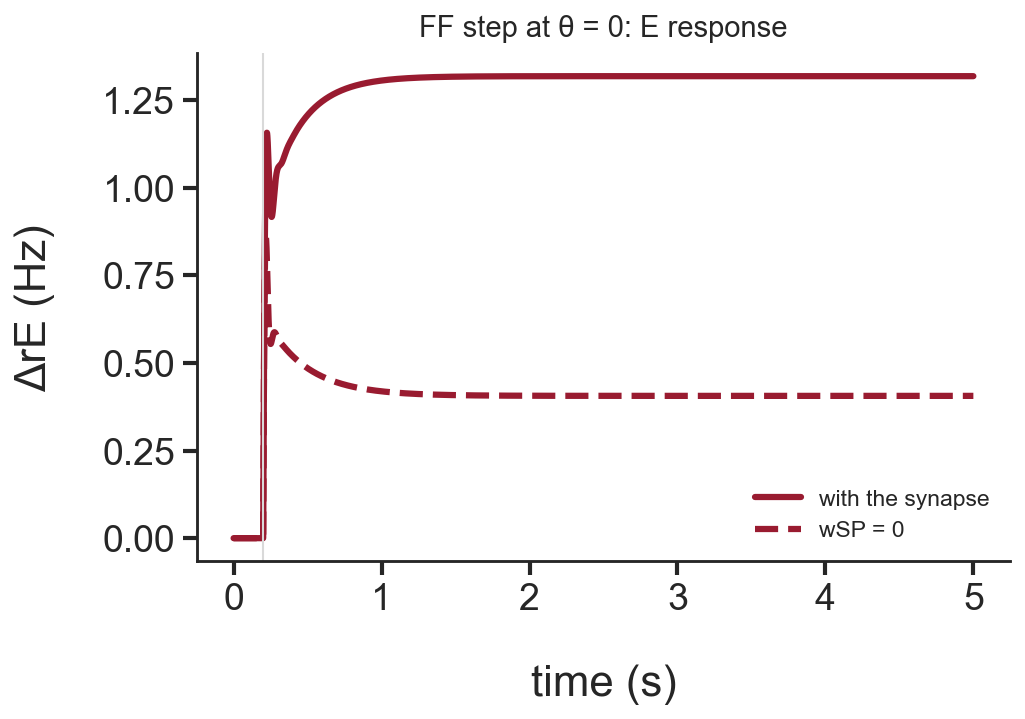

In [365]:
# single-configuration view of the FF-amplification claim: drive the FF
# input, record E — with the synapse vs with it removed (wSP = 0)
W_RUN0 = W_RUN.copy()
W_RUN0[2, 1] = 0.0
t_on = 200

fig, ax = plt.subplots(1, 1, figsize=(7, 4.4))
for W, ls, label in ((W_RUN, '-', 'with the synapse'), (W_RUN0, '--', 'wSP = 0')):
    c = VIP_circuit_neuromod(W, theta=0.0)
    sim = c.simulate_dynamics(end_sim=5000, dt=0.05, t_stim_FF=t_on)
    ax.plot(sim["time"] / 1000, sim["rE"] - c.rE0, color=color_FF,
            ls=ls, label=label)
ax.axvline(t_on / 1000, color='0.85', lw=1)
ax.set_xlabel('time (s)')
ax.set_ylabel('ΔrE (Hz)')
ax.set_title('FF step at θ = 0: E response', fontsize=14, pad=8)
ax.legend(fontsize=11)
plt.savefig(saving_directory + "FF_step_E_response.pdf")

### Panel B - Gain and stability on the same $w_{SP}$ axis

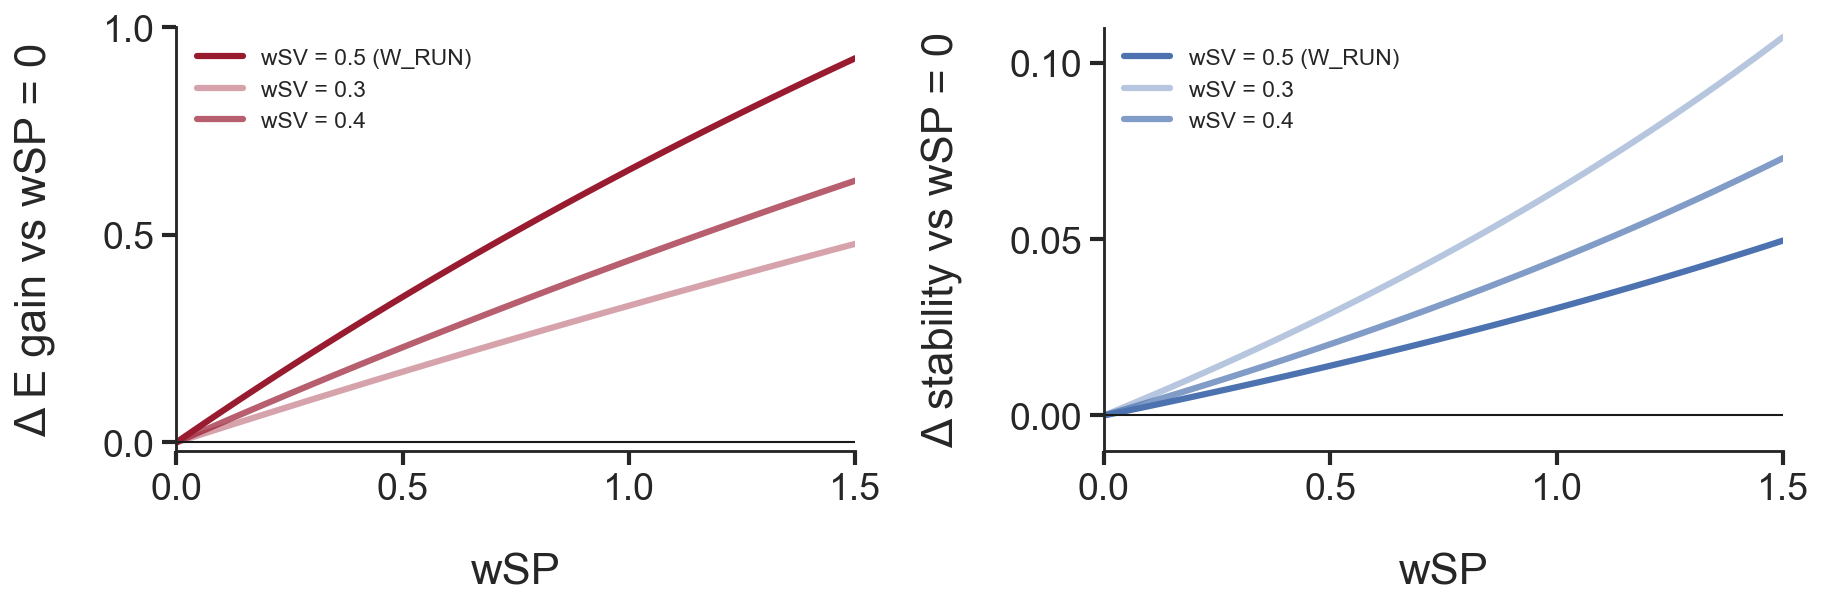

wSV = 0.3: viable on 100% of the wSP axis; Δgain_FF +0.00..+0.48; Δstability +0.000..+0.107
wSV = 0.4: viable on 100% of the wSP axis; Δgain_FF +0.00..+0.63; Δstability +0.000..+0.073
wSV = 0.5: viable on 100% of the wSP axis; Δgain_FF +0.00..+0.93; Δstability +0.000..+0.050


In [366]:
# same single-configuration claim, gain and stability side by side on the wSP axis
wsp_line = np.linspace(0.0, 1.5, 76)
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.4))

ax = axes[0]
amps = {}
# for th, alpha, label in ((0.0, 0.45, 'low arousal (θ=0)'), (1.0, 1.0, 'high arousal (θ=1)')):
th, alpha, label = 0.0, 1.0, f'wSV = {W_RUN[2, 3]:g} (W_RUN)'
r = VIP_circuit_neuromod(W_RUN, theta=th).calculate_linear_theory_general(
    mode="weights", grid_search=False, w1_name="wSP", w1_vals=wsp_line)
g = np.where(r["maxEV"] <= -0.05, r["gain_FF"], np.nan)
ax.plot(wsp_line, g - r["gain_FF"][0], color=color_FF, alpha=alpha, label=label)
gB = g[np.argmin(np.abs(wsp_line - W_RUN[2, 1]))]
amps[th] = (g[0], gB)
for wsv_ex, al_ex in ((0.3, 0.4), (0.4, 0.7)):
    W_sv = W_RUN.copy()
    W_sv[2, 3] = wsv_ex
    r_sv = VIP_circuit_neuromod(W_sv, theta=0.0).calculate_linear_theory_general(
        mode="weights", grid_search=False, w1_name="wSP", w1_vals=wsp_line)
    g_sv = np.where(r_sv["maxEV"] <= -0.05, r_sv["gain_FF"], np.nan)
    ax.plot(wsp_line, g_sv - r_sv["gain_FF"][0], color=color_FF, alpha=al_ex, label=f'wSV = {wsv_ex:g}')
# ax.plot(W_RUN[2, 1], gB, marker='o', ms=8, color=color_FF, alpha=alpha)
# ax.text(W_RUN[2, 1] + 0.04, gB, f"×{gB / g[0]:.2f}", va='center', fontsize=12,
#         color=color_FF, alpha=max(alpha, 0.6))


# ax.plot(0, amps[0.0][0], marker='o', ms=8, color='0.4')
# ax.text(0.06, amps[0.0][0] + 0.005, f'ablation ({amps[0.0][0]:.2f}, both θ)',
        # fontsize=11, color='0.4', va='bottom')
# ax.axvline(W_RUN[2, 1], color='0.75', lw=1, ls=':')
ax.set_xlabel('wSP')
ax.axhline(0, color='k', lw=1)
ax.set_ylabel('Δ E gain vs wSP = 0')
# ax.set_title('gain_FF vs wSP', fontsize=14, pad=8)
ax.legend(fontsize=11, loc='upper left')
ax.set_xlim(0, 1.5)
ax.set_xticks([0.0, 0.5, 1.0, 1.5])
ax.set_ylim(-0.02, 1.0)
ax.set_yticks([0.0, 0.5, 1.0])

ax = axes[1]
# for th, alpha, label in ((0.0, 0.45, 'low arousal (θ=0)'), (1.0, 1.0, 'high arousal (θ=1)')):
th, alpha, label = 0.0, 1.0, f'wSV = {W_RUN[2, 3]:g} (W_RUN)'
r = VIP_circuit_neuromod(W_RUN, theta=th).calculate_linear_theory_general(
    mode="weights", grid_search=False, w1_name="wSP", w1_vals=wsp_line)
stab = -r["maxEV"]
ax.plot(wsp_line, stab - stab[0], color=stability_color, alpha=alpha, label=label)
sB = stab[np.argmin(np.abs(wsp_line - W_RUN[2, 1]))]
for wsv_ex, al_ex in ((0.3, 0.4), (0.4, 0.7)):
    W_sv = W_RUN.copy()
    W_sv[2, 3] = wsv_ex
    r_sv = VIP_circuit_neuromod(W_sv, theta=0.0).calculate_linear_theory_general(
        mode="weights", grid_search=False, w1_name="wSP", w1_vals=wsp_line)
    ax.plot(wsp_line, -r_sv["maxEV"] + r_sv["maxEV"][0], color=stability_color, alpha=al_ex,
            label=f'wSV = {wsv_ex:g}')
# ax.plot(W_RUN[2, 1], sB, marker='o', ms=8, color=stability_color, alpha=alpha)
# print(f"theta={th:g}: stability {stab[0]:.3f} (wSP=0) -> {sB:.3f} (W_RUN) "
#         f"-> {stab[-1]:.3f} (wSP=1.5); most stable at "
#         f"wSP={wsp_line[np.argmax(stab)]:.2f}")

# ax.axhline(0, color='k', lw=1)
# ax.axhline(0.05, color='0.7', lw=1, ls=':')
# ax.text(0.995, 0.052, 'viability margin', color='0.55', fontsize=10,
#         transform=ax.get_yaxis_transform(), ha='right', va='bottom')
# ax.axvline(W_RUN[2, 1], color='0.75', lw=1, ls=':')
ax.set_xlabel('wSP')
ax.axhline(0, color='k', lw=1)
ax.set_ylabel('Δ stability vs wSP = 0')
# ax.set_title('stability vs wSP', fontsize=14, pad=8)
ax.legend(fontsize=11, loc='upper left')
ax.set_xlim(0, 1.5)
ax.set_xticks([0.0, 0.5, 1.0, 1.5])
ax.set_ylim(-0.01, 0.11)
ax.set_yticks([0.0, 0.05, 0.1])
fig.tight_layout()
plt.savefig(saving_directory + "FF_gain_stability_wSP.pdf")
plt.show()

for wsv_ex in (0.3, 0.4, W_RUN[2, 3]):
    W_sv = W_RUN.copy()
    W_sv[2, 3] = wsv_ex
    r_sv = VIP_circuit_neuromod(W_sv, theta=0.0).calculate_linear_theory_general(
        mode="weights", grid_search=False, w1_name="wSP", w1_vals=wsp_line)
    viable = r_sv["maxEV"] <= -0.05
    g_sv = np.where(viable, r_sv["gain_FF"], np.nan)
    dg = g_sv - r_sv["gain_FF"][0]
    ds = -r_sv["maxEV"] + r_sv["maxEV"][0]
    print(f"wSV = {wsv_ex:g}: viable on {100 * viable.mean():.0f}% of the wSP axis; "
          f"Δgain_FF {np.nanmin(dg):+.2f}..{np.nanmax(dg):+.2f}; "
          f"Δstability {ds.min():+.3f}..{ds.max():+.3f}")

Supp - panel A

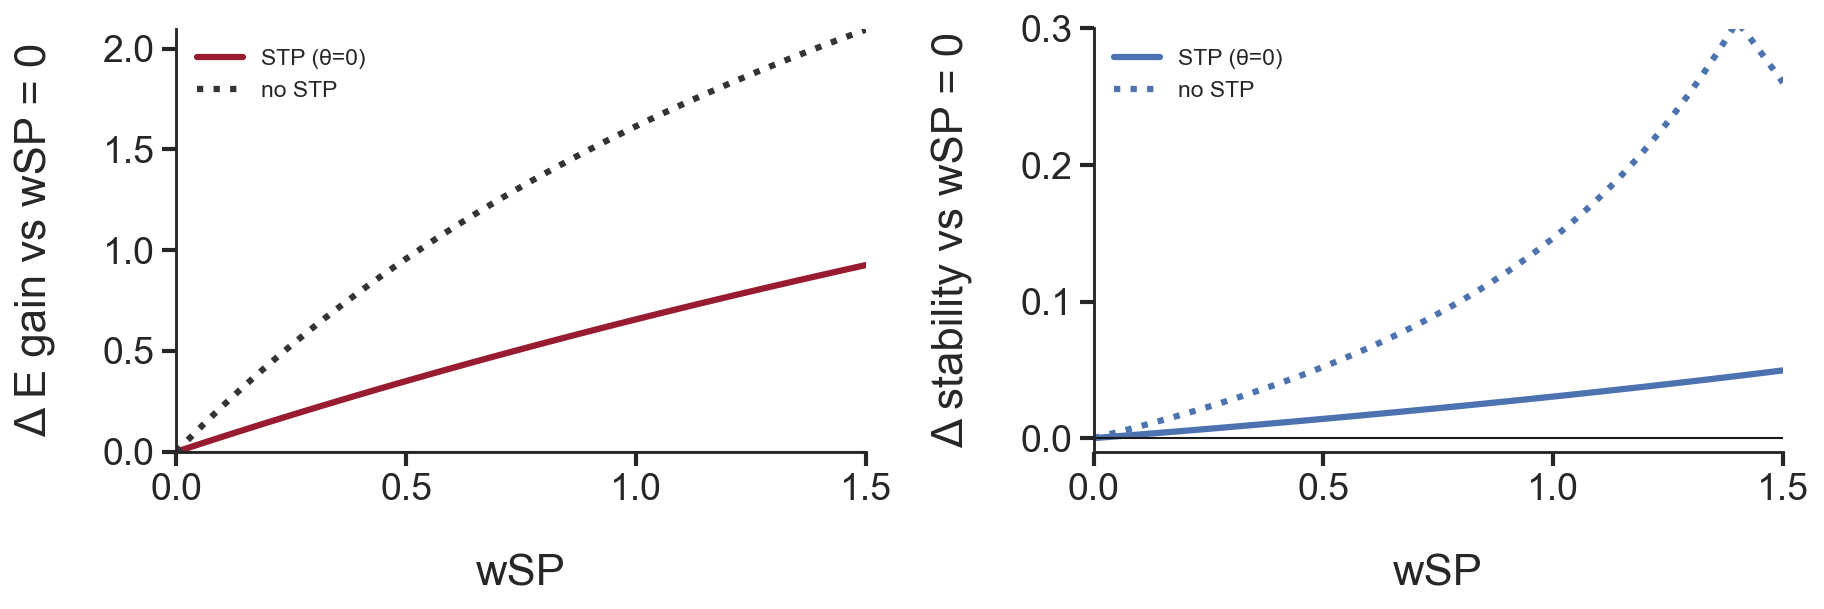

STP (θ=0): Δgain_FF +0.926 and Δstability +0.050 at wSP = 1.5; viable on 100% of the axis
no STP: Δgain_FF +2.094 and Δstability +0.260 at wSP = 1.5; viable on 100% of the axis


In [ ]:
def static_noSTP_c(W):
    c = VIP_circuit_neuromod(W)
    c.tau_SP = 0.0
    c.U_SP_base = c.U_SP_high = 1.0
    c.set_arousal(0.0)
    return c

wsp_line1 = np.linspace(0.0, 1.5, 76)
r_stp = VIP_circuit_neuromod(W_RUN, theta=0.0).calculate_linear_theory_general(
    mode="weights", grid_search=False, w1_name="wSP", w1_vals=wsp_line1)
r_nst = static_noSTP_c(W_RUN).calculate_linear_theory_general(
    mode="weights", grid_search=False, w1_name="wSP", w1_vals=wsp_line1)
runs1 = [(r_stp, color_FF, '-', 'STP (θ=0)'), (r_nst, '0.2', ':', 'no STP')]

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.4))
ax = axes[0]
for r1, col, ls, lab in runs1:
    g1 = np.where(r1["maxEV"] <= -0.05, r1["gain_FF"], np.nan)
    ax.plot(wsp_line1, g1 - r1["gain_FF"][0], color=col, ls=ls, label=lab)
ax.axhline(0, color='k', lw=1)
ax.set_xlabel('wSP')
ax.set_ylabel('Δ E gain vs wSP = 0')
ax.legend(fontsize=11, loc='upper left')
ax.set_xlim(0, 1.5)
ax.set_xticks([0.0, 0.5, 1.0, 1.5])
ax.set_ylim(0, 2.1)

ax = axes[1]
for r1, col, ls, lab in runs1:
    stab1 = -r1["maxEV"]
    ax.plot(wsp_line1, stab1 - stab1[0], color=stability_color, ls=ls, label=lab)
ax.axhline(0, color='k', lw=1)
ax.set_xlabel('wSP')
ax.set_ylabel('Δ stability vs wSP = 0')
ax.legend(fontsize=11, loc='upper left')
ax.set_xlim(0, 1.5)
ax.set_xticks([0.0, 0.5, 1.0, 1.5])
ax.set_ylim(-0.01, 0.3)
fig.tight_layout()
plt.savefig(saving_directory + "FF_gain_stability_wSP_STP_vs_static.pdf")
plt.show()

i_own1 = int(np.argmin(np.abs(wsp_line1 - W_RUN[2, 1])))
for r1, _, _, lab in runs1:
    dg1 = r1["gain_FF"][i_own1] - r1["gain_FF"][0]
    ds1 = -r1["maxEV"][i_own1] + r1["maxEV"][0]
    viab1 = (r1["maxEV"] <= -0.05).mean()
    print(f"{lab}: Δgain_FF {dg1:+.3f} and Δstability {ds1:+.3f} at wSP = {wsp_line1[i_own1]:g}; "
          f"viable on {100 * viab1:.0f}% of the axis")

In [ ]:
# theta_vals = np.linspace(0, 1, 101)
# W_RUN0 = W_RUN.copy()
# W_RUN0[2, 1] = 0.0
# s_full = VIP_circuit_neuromod(W_RUN).sweep_arousal(theta_vals)
# s_abl = VIP_circuit_neuromod(W_RUN0).sweep_arousal(theta_vals)

# fig, ax = plt.subplots(figsize=(6.5, 4))
# ax.plot(theta_vals, s_full["gain_FF"], color=color_FF, label='full network')
# ax.plot(theta_vals, s_abl["gain_FF"], color=color_FF, ls='--', label='wSP = 0')
# ax.set_xlabel('arousal θ')
# ax.set_ylabel('gain_FF')
# ax.set_title('FF gain: PV→SST helps', fontsize=15, pad=10)
# ax.legend(fontsize=12)
# fig.tight_layout()
# plt.show()
# print(f"FF benefit of wSP: {s_full['gain_FF'][0] - s_abl['gain_FF'][0]:+.3f} at θ=0, "
#       f"{s_full['gain_FF'][-1] - s_abl['gain_FF'][-1]:+.3f} at θ=1")

# FB stimulation


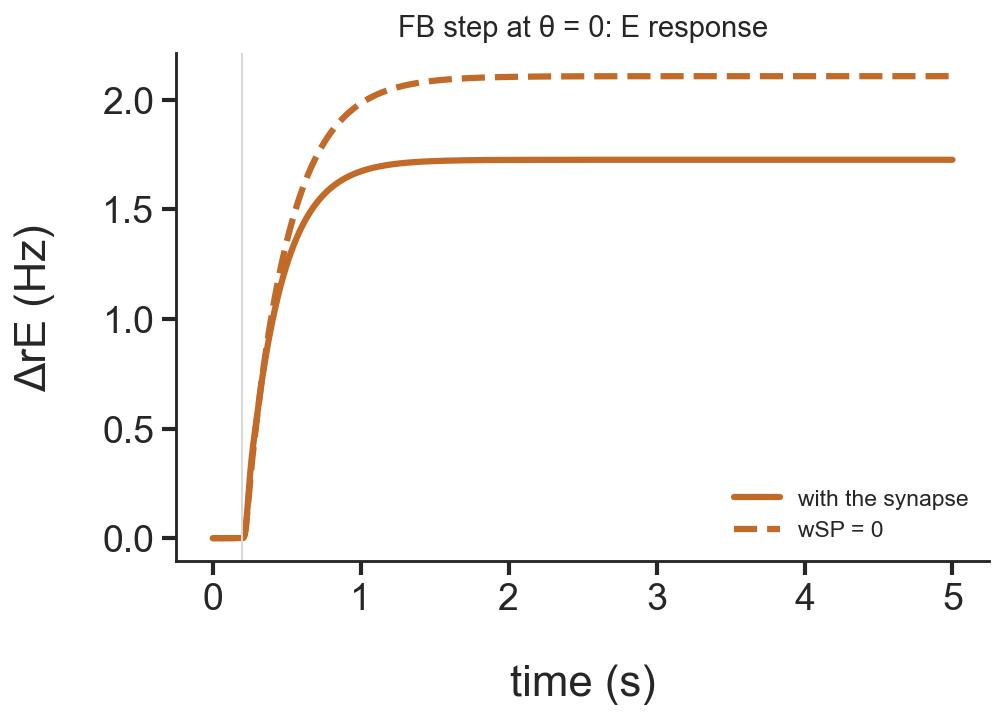

In [ ]:
W_RUN0 = W_RUN.copy()
W_RUN0[2, 1] = 0.0
t_on = 200

fig, ax = plt.subplots(1, 1, figsize=(7, 4.4))
for W, ls, label in ((W_RUN, '-', 'with the synapse'), (W_RUN0, '--', 'wSP = 0')):
    c = VIP_circuit_neuromod(W, theta=0.0)
    sim = c.simulate_dynamics(end_sim=5000, dt=0.05, t_stim_FB=t_on)
    ax.plot(sim["time"] / 1000, sim["rE"] - c.rE0, color=color_FB,
            ls=ls, label=label)
ax.axvline(t_on / 1000, color='0.85', lw=1)
ax.set_xlabel('time (s)')
ax.set_ylabel('ΔrE (Hz)')
ax.set_title('FB step at θ = 0: E response', fontsize=14, pad=8)
ax.legend(fontsize=11)
plt.savefig(saving_directory + "FB_step_E_response.pdf")

### gain_FB vs the VIP→SST weight (supp)

In [369]:
# # gain_FB as a function of the VIP->SST weight (with the static no-STP control)
# def static_noSTP_c(W):
#     c = VIP_circuit_neuromod(W)
#     c.tau_SP = 0.0
#     c.U_SP_base = c.U_SP_high = 1.0
#     c.set_arousal(0.0)
#     return c

# wsv_sw = np.linspace(0.0, 1.0, 101)
# fig, ax = plt.subplots(figsize=(6.5, 4.2))
# # for th, alpha, label in ((0.0, 0.45, 'low arousal (θ=0)'), (1.0, 1.0, 'high arousal (θ=1)')):
# th, alpha, label = 1.0, 1.0, 'high arousal (θ=1)'
# r = VIP_circuit_neuromod(W_RUN, theta=th).calculate_linear_theory_general(
#     mode="weights", grid_search=False, w1_name="wSV", w1_vals=wsv_sw)
# g = np.where(r["maxEV"] <= -0.05, r["gain_FB"], np.nan)
# ax.plot(wsv_sw, g, color=color_FB, alpha=alpha, label=label)
# lim = wsv_sw[np.isfinite(g)]
# if len(lim):
#     print(f"theta={th:g}: viable wSV window [{lim.min():.2f}, {lim.max():.2f}], "
#             f"gain_FB up to {np.nanmax(g):.2f} at the edge")
# else:
#     print(f"theta={th:g}: unstable at every wSV")
# r_st = static_noSTP_c(W_RUN).calculate_linear_theory_general(
#     mode="weights", grid_search=False, w1_name="wSV", w1_vals=wsv_sw)
# g_st = np.where(r_st["maxEV"] <= -0.05, r_st["gain_FB"], np.nan)
# ax.plot(wsv_sw, g_st, color='0.2', ls=':', label='static, no STP')
# lim = wsv_sw[np.isfinite(g_st)]
# # if len(lim):
# #     print(f"static: gain_FB {np.nanmax(g_st):.2f} max, viable to wSV ~ {lim.max():.2f}")
# # else:
# #     print("static: unstable at every wSV — the undepressed PV->SST coupling alone "
# #           "removes the circuit's viability")
# # ax.axvline(W_RUN[2, 3], color='0.6', lw=1, ls=':')
# ax.set_xlabel('wSV (structural)')
# ax.set_ylabel('gain_FB')
# ax.set_title('gain_FB vs the VIP→SST weight', fontsize=15, pad=10)
# ax.legend(fontsize=11)
# fig.tight_layout()
# plt.show()


### Stability vs the VIP→SST weight (supp)

In [370]:
# # stability as a function of the VIP->SST weight (with the static no-STP control)
# def static_noSTP_c(W):
#     c = VIP_circuit_neuromod(W)
#     c.tau_SP = 0.0
#     c.U_SP_base = c.U_SP_high = 1.0
#     c.set_arousal(0.0)
#     return c

# wsv_sw = np.linspace(0.0, 1.0, 101)
# fig, ax = plt.subplots(figsize=(6.5, 4.2))
# # for th, alpha, label in ((0.0, 0.45, 'low arousal (θ=0)'), (1.0, 1.0, 'high arousal (θ=1)')):
# th, alpha, label = 1.0, 1.0, 'high arousal (θ=1)'
# r = VIP_circuit_neuromod(W_RUN, theta=th).calculate_linear_theory_general(
#     mode="weights", grid_search=False, w1_name="wSV", w1_vals=wsv_sw)
# ax.plot(wsv_sw, r["maxEV"], color=stability_color, alpha=alpha, label=label)
# cross0 = wsv_sw[np.where(r["maxEV"] > 0)[0]]
# print(f"theta={th:g}: most stable at wSV={wsv_sw[np.argmin(r['maxEV'])]:.2f}; " +
#         (f"unstable from wSV ~ {cross0.min():.2f}" if len(cross0) else "stable in range"))

# r_st = static_noSTP_c(W_RUN).calculate_linear_theory_general(
#     mode="weights", grid_search=False, w1_name="wSV", w1_vals=wsv_sw)
# ax.plot(wsv_sw, r_st["maxEV"], color=stability_color, ls=':', label='static, no STP')
# unst = wsv_sw[np.where(r_st["maxEV"] > 0)[0]]
# # print(f"static: most stable at wSV={wsv_sw[np.argmin(r_st['maxEV'])]:.2f} "
# #       f"({np.min(r_st['maxEV']):.3f}); " +
# #       (f"unstable from wSV ~ {unst.min():.2f}" if len(unst) else "stable in range"))
# ax.axhline(0, color='k', lw=1)
# # ax.axhline(-0.05, color='0.7', lw=1, ls=':')
# # ax.text(0.995, -0.048, 'viability margin', color='0.55', fontsize=10, ha='right', va='bottom')
# # ax.axvline(W_RUN[2, 3], color='0.6', lw=1, ls=':')
# ax.set_xlabel('wSV (structural)')
# ax.set_ylabel('max Re λ')
# ax.set_title('stability vs the VIP→SST weight', fontsize=15, pad=10)
# ax.legend(fontsize=11)
# fig.tight_layout()
# plt.show()

### Panel E - The same $w_{SP}$-axis view for the FB channel — with and without STP


high arousal (θ=1): Δstability +0.017 at W_RUN (from 0.097 at wSP=0); stable in range
static, no STP: Δstability +0.260 at W_RUN (from 0.097 at wSP=0); stable in range


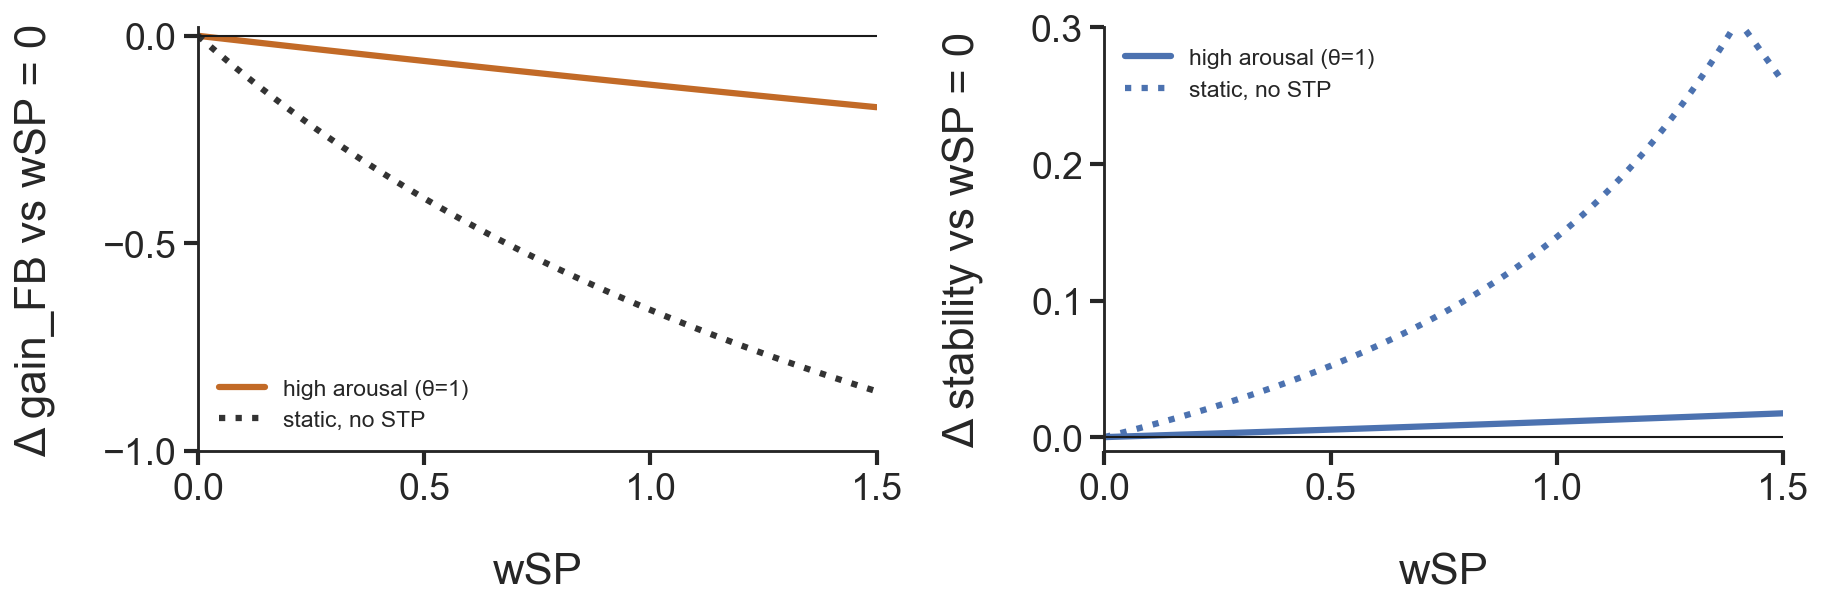

In [ ]:
def static_noSTP_c(W):
    c = VIP_circuit_neuromod(W)
    c.tau_SP = 0.0
    c.U_SP_base = c.U_SP_high = 1.0
    c.set_arousal(0.0)   # efficacy factor 1 at every theta
    return c

wsp_line = np.linspace(0.0, 1.5, 76)
runs = []
# for th, alpha, label in ((0.0, 0.45, 'low arousal (θ=0)'), (1.0, 1.0, 'high arousal (θ=1)')):
th, alpha, label = 1.0, 1.0, 'high arousal (θ=1)'
r = VIP_circuit_neuromod(W_RUN, theta=th).calculate_linear_theory_general(
    mode="weights", grid_search=False, w1_name="wSP", w1_vals=wsp_line)
runs.append((r, color_FB, alpha, '-', label))

r_st = static_noSTP_c(W_RUN).calculate_linear_theory_general(
    mode="weights", grid_search=False, w1_name="wSP", w1_vals=wsp_line)
runs.append((r_st, '0.2', 1.0, ':', 'static, no STP'))

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.4))
ax = axes[0]
for r, col, alpha, ls, label in runs:
    g = np.where(r["maxEV"] <= -0.05, r["gain_FB"], np.nan)
    ax.plot(wsp_line, g - r["gain_FB"][0], color=col, alpha=alpha, ls=ls, label=label)
    gB = g[np.argmin(np.abs(wsp_line - W_RUN[2, 1]))]
    # if np.isfinite(gB):
        # ax.plot(W_RUN[2, 1], gB, marker='o', ms=8, color=col, alpha=alpha)
        # ax.text(W_RUN[2, 1] + 0.04, gB, f"×{gB / g[0]:.2f}", va='center', fontsize=12,
                # color=col, alpha=max(alpha, 0.6))
    viable = wsp_line[np.isfinite(g)]
    # print(f"{label}: gain_FB {g[0]:.3f} (wSP=0) -> "
        #   + (f"{gB:.3f} (W_RUN); " if np.isfinite(gB) else "not viable at W_RUN; ")
        #   + (f"viable to wSP ~ {viable.max():.2f}" if len(viable) else "never viable"))
# ax.plot(0, runs[0][0]["gain_FB"][0], marker='o', ms=8, color='0.4')
# ax.text(0.06, runs[0][0]["gain_FB"][0], 'ablation (shared, all curves)',
#         fontsize=11, color='0.4', va='bottom')
# ax.axvline(W_RUN[2, 1], color='0.75', lw=1, ls=':')
ax.set_xlabel('wSP')
ax.axhline(0, color='k', lw=1)
ax.set_ylabel('Δ gain_FB vs wSP = 0')
ax.set_xlim(0, 1.5)
ax.set_xticks([0.0, 0.5, 1.0, 1.5])
ax.set_ylim(-1.0,0.02)
ax.set_yticks([-1.0, -0.5, 0.0])
# ax.set_title('gain_FB vs wSP', fontsize=14, pad=8)
ax.legend(fontsize=11)

ax = axes[1]
for r, col, alpha, ls, label in runs:
    stab = -r["maxEV"]
    ax.plot(wsp_line, stab - stab[0], color=stability_color,
            alpha=alpha, ls=ls, label=label)
    sB = stab[np.argmin(np.abs(wsp_line - W_RUN[2, 1]))]
    # if col == color_FB:
    #     ax.plot(W_RUN[2, 1], sB, marker='o', ms=8, color=stability_color, alpha=alpha)
    dead = wsp_line[stab < 0]
    print(f"{label}: Δstability {sB - stab[0]:+.3f} at W_RUN (from {stab[0]:.3f} at wSP=0); "
          + (f"unstable from wSP ~ {dead.min():.2f}" if len(dead) else "stable in range"))
ax.axhline(0, color='k', lw=1)
# ax.axhline(0.05, color='0.7', lw=1, ls=':')
# ax.text(0.995, 0.052, 'viability margin', color='0.55', fontsize=10,
#         transform=ax.get_yaxis_transform(), ha='right', va='bottom')
# ax.axvline(W_RUN[2, 1], color='0.75', lw=1, ls=':')
ax.set_xlabel('wSP')
ax.set_ylabel('Δ stability vs wSP = 0')
# ax.set_title('stability vs wSP', fontsize=14, pad=8)
ax.legend(fontsize=11)
ax.set_xlim(0, 1.5)
ax.set_xticks([0.0, 0.5, 1.0, 1.5])
ax.set_ylim(-0.01, 0.3)
ax.set_yticks([0.0, 0.1, 0.2, 0.3])
fig.tight_layout()
plt.savefig(saving_directory + "FB_gain_stability_wSP.pdf")
plt.show()

In [372]:
# def static_noSTP(W):
#     c = VIP_circuit_neuromod(W)
#     c.tau_SP = 0.0
#     c.U_SP_base = c.U_SP_high = 1.0
#     c.set_arousal(0.0)   # efficacy factor 1 at every theta
#     return c

# s_stat = static_noSTP(W_RUN).sweep_arousal(theta_vals)

# fig, ax = plt.subplots(figsize=(6.5, 4))
# ax.plot(theta_vals, s_full["gain_FB"], color=color_FB, label='full network (depressing)')
# ax.plot(theta_vals, s_stat["gain_FB"], color='0.2', ls=':', label='static, no STP')
# ax.set_xlabel('arousal θ')
# ax.set_ylabel('gain_FB')
# ax.set_title('FB gain: rises only with STP', fontsize=15, pad=10)
# ax.legend(fontsize=12)
# fig.tight_layout()
# plt.show()
# print(f"depressing: FB {s_full['gain_FB'][0]:.3f} -> {s_full['gain_FB'][-1]:.3f} "
#       f"(monotone: {bool(np.all(np.diff(s_full['gain_FB']) > 0))}) | "
#       f"static no-STP: FB = {s_stat['gain_FB'][0]:.3f}, flat")


### Supp plot -  E gain over the (wSP, wSV) plane, each channel in its own regime

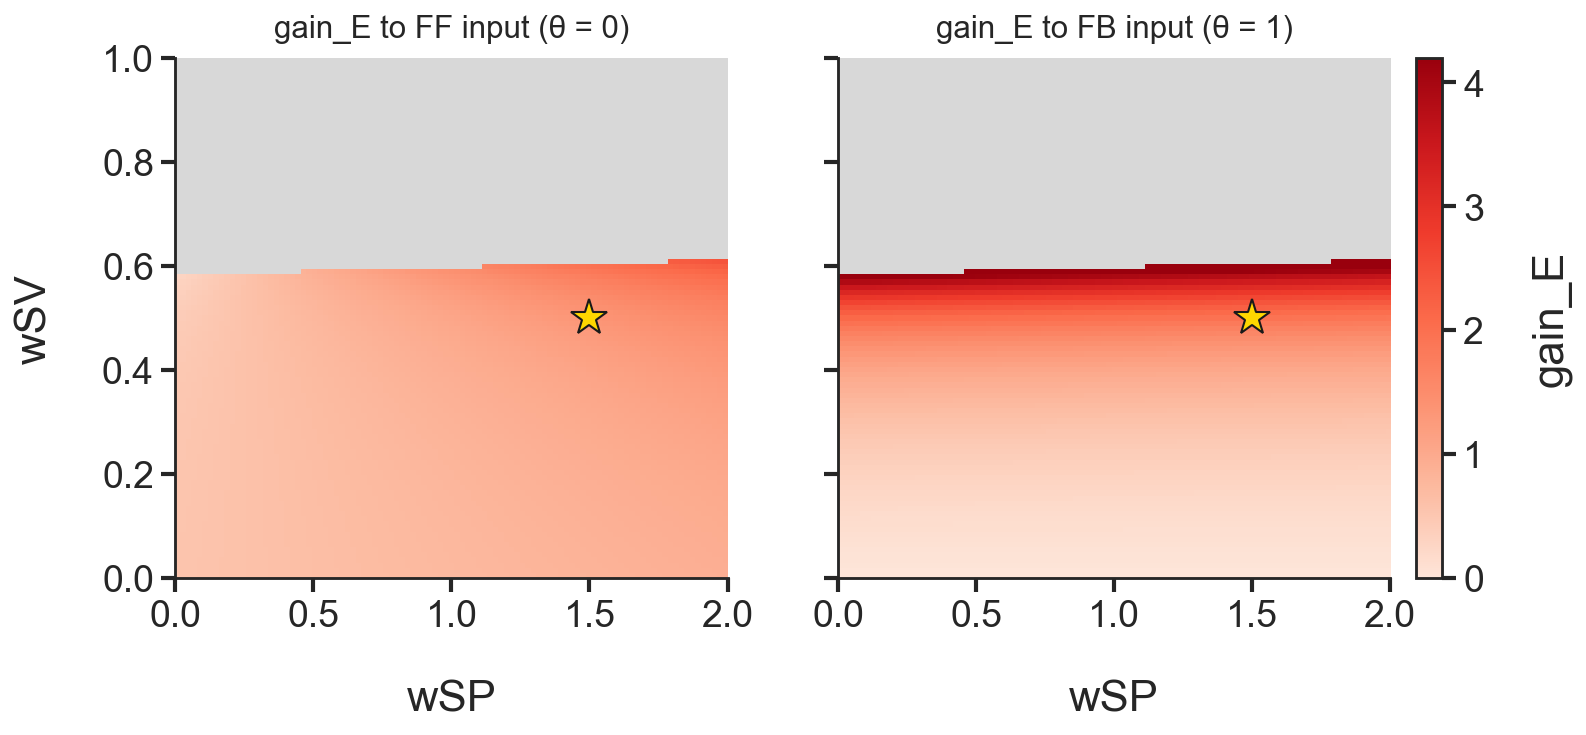

unstable at either end (gray): 40.3%; at W_RUN's star: gain_FF(θ=0) = 1.33, gain_FB(θ=1) = 1.93 (display clipped at 4.2)


In [ ]:
from matplotlib.colors import LinearSegmentedColormap

hex_red = ['#fee5d9', '#fcbba1', '#fc9272', '#fb6a4a', '#ef3b2c', '#cb181d', '#99000d']
cmap_gain = LinearSegmentedColormap.from_list(
    'reds_gain', [[int(h[i:i + 2], 16) / 255 for i in (1, 3, 5)] for h in hex_red], N=256)
cmap_gain.set_bad(color='0.85')

wsp_hm = np.linspace(0.0, 2.0, 101)
wsv_hm = np.linspace(0.0, 1.0, 101)
res0_hm = VIP_circuit_neuromod(W_RUN, theta=0.0).calculate_linear_theory_general(
    mode="weights", grid_search=False, w1_name="wSP", w1_vals=wsp_hm,
    w2_name="wSV", w2_vals=wsv_hm)
res1_hm = VIP_circuit_neuromod(W_RUN, theta=1.0).calculate_linear_theory_general(
    mode="weights", grid_search=False, w1_name="wSP", w1_vals=wsp_hm,
    w2_name="wSV", w2_vals=wsv_hm)
unstable_hm = ~((res0_hm["maxEV"] <= -0.05) & (res1_hm["maxEV"] <= -0.05))
panels = [("gain_FF", res0_hm, "gain_E to FF input (θ = 0)"),
          ("gain_FB", res1_hm, "gain_E to FB input (θ = 1)")]
vmax_hm = np.nanpercentile(np.where(unstable_hm, np.nan,
                                    np.maximum(res0_hm["gain_FF"], res1_hm["gain_FB"])), 98)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharey=True)
for ax, (key, res, title) in zip(axes, panels):
    M = res[key].copy()
    M[unstable_hm] = np.nan
    im = ax.imshow(M.T, origin='lower', aspect='auto', cmap=cmap_gain,
                   extent=[0, 2, 0, 1], vmin=0, vmax=vmax_hm)
    ax.plot(W_RUN[2, 1], W_RUN[2, 3], marker='*', ms=18, mfc='gold', mec='k')
    ax.set_title(title, fontsize=15, pad=10)
    ax.set_xlabel('wSP')
axes[0].set_ylabel('wSV')
cbar = fig.colorbar(im, ax=list(axes), fraction=0.03, pad=0.02)
cbar.set_label('gain_E')
plt.savefig(saving_directory + "gain_FF_FB_wSP_wSV.pdf")
plt.show()

iS = int(np.argmin(np.abs(wsp_hm - W_RUN[2, 1])))
jS = int(np.argmin(np.abs(wsv_hm - W_RUN[2, 3])))
print(f"unstable at either end (gray): {unstable_hm.mean():.1%}; at W_RUN's star: "
      f"gain_FF(θ=0) = {res0_hm['gain_FF'][iS, jS]:.2f}, "
      f"gain_FB(θ=1) = {res1_hm['gain_FB'][iS, jS]:.2f} (display clipped at {vmax_hm:.1f})")


### Supp plot — stability over the $(w_{SP}, w_{SV})$ plane

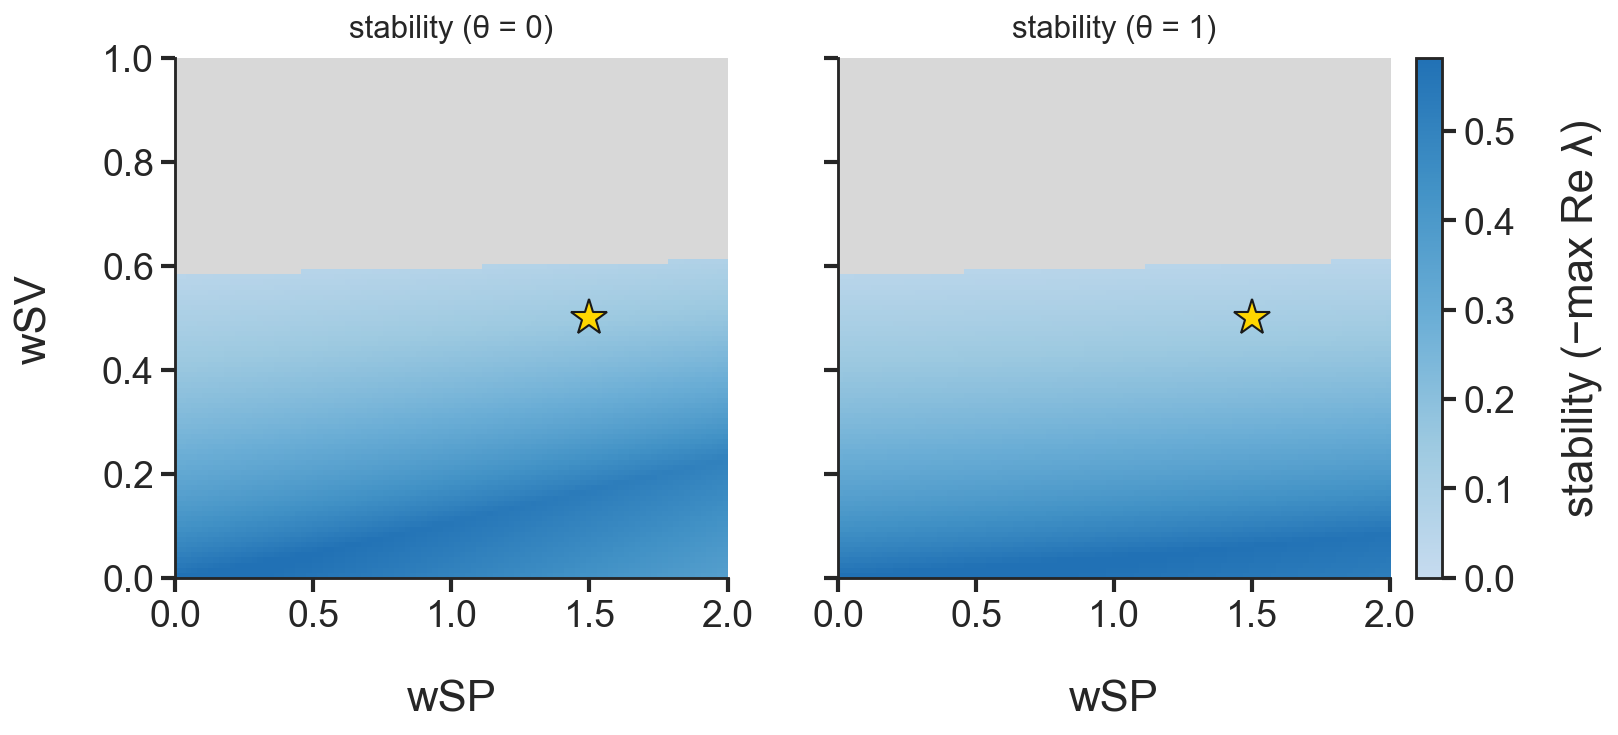

at W_RUN's star: stability 0.146 (θ=0) -> 0.114 (θ=1); most stable point of the viable plane (θ=0): 0.600 at (wSP, wSV) = (0.12, 0.00); θ=1 max 0.600 (display clipped at 0.58)


In [374]:
# stability over the same (wSP, wSV) plane, at the two arousal ends — the
# companion of the gain maps above (runs after that cell: reuses res0_hm,
# res1_hm, unstable_hm, wsp_hm, wsv_hm; same gray mask and star convention)
hex_blue = ['#c6dbef', '#9ecae1', '#6baed6', '#4292c6', '#2171b5']
cmap_stab = LinearSegmentedColormap.from_list(
    'blues_stab', [[int(h[i:i + 2], 16) / 255 for i in (1, 3, 5)] for h in hex_blue], N=256)
cmap_stab.set_bad(color='0.85')

vmax_s = np.nanpercentile(np.where(unstable_hm, np.nan,
                                   np.maximum(-res0_hm["maxEV"], -res1_hm["maxEV"])), 98)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharey=True)
for ax, (res, title) in zip(axes, [(res0_hm, 'stability (θ = 0)'),
                                   (res1_hm, 'stability (θ = 1)')]):
    M = -res["maxEV"].copy()
    M[unstable_hm] = np.nan
    im = ax.imshow(M.T, origin='lower', aspect='auto', cmap=cmap_stab,
                   extent=[0, 2, 0, 1], vmin=0, vmax=vmax_s)
    ax.plot(W_RUN[2, 1], W_RUN[2, 3], marker='*', ms=18, mfc='gold', mec='k')
    ax.set_title(title, fontsize=15, pad=10)
    ax.set_xlabel('wSP')
axes[0].set_ylabel('wSV')
cbar = fig.colorbar(im, ax=list(axes), fraction=0.03, pad=0.02)
cbar.set_label('stability (−max Re λ)')
plt.savefig(saving_directory + "stability_wSP_wSV.pdf")
plt.show()

iS = int(np.argmin(np.abs(wsp_hm - W_RUN[2, 1])))
jS = int(np.argmin(np.abs(wsv_hm - W_RUN[2, 3])))
s0map = np.where(unstable_hm, np.nan, -res0_hm["maxEV"])
s1map = np.where(unstable_hm, np.nan, -res1_hm["maxEV"])
i0, j0 = np.unravel_index(np.nanargmax(s0map), s0map.shape)
print(f"at W_RUN's star: stability {-res0_hm['maxEV'][iS, jS]:.3f} (θ=0) -> "
      f"{-res1_hm['maxEV'][iS, jS]:.3f} (θ=1); most stable point of the viable plane "
      f"(θ=0): {np.nanmax(s0map):.3f} at (wSP, wSV) = ({wsp_hm[i0]:.2f}, {wsv_hm[j0]:.2f}); "
      f"θ=1 max {np.nanmax(s1map):.3f} (display clipped at {vmax_s:.2f})")

## Panel F - The full network on the arousal axis

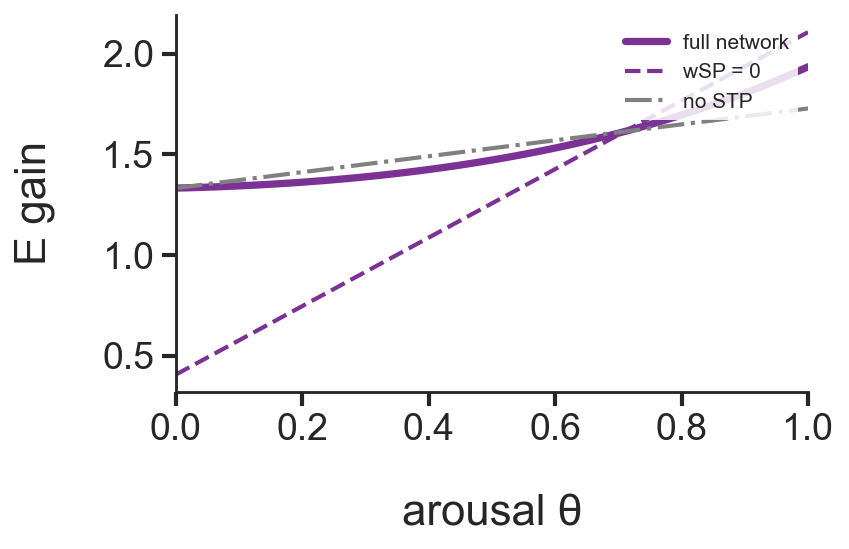

In [375]:
theta_vals = np.linspace(0, 1, 101)
W_RUN0 = W_RUN.copy()
W_RUN0[2, 1] = 0.0
s_full = VIP_circuit_neuromod(W_RUN).sweep_arousal(theta_vals)
s_abl = VIP_circuit_neuromod(W_RUN0).sweep_arousal(theta_vals)
# VIP->SST ablation: with wSV = 0 the FB channel is structurally dead
# (N_FB ~ wSV, so gain_FB = 0) and the mix is (1-theta)*gain_FF(theta)
W_RUN0V = W_RUN.copy()
W_RUN0V[2, 3] = 0.0
s_ablV = VIP_circuit_neuromod(W_RUN0V).sweep_arousal(theta_vals)
# static no-STP control at the SAME wSP (cSP = 1 at every theta): the circuit
# is theta-flat, so its mix is pure input routing between two fixed gains
c_stat = VIP_circuit_neuromod(W_RUN)
c_stat.tau_SP = 0.0
c_stat.U_SP_base = c_stat.U_SP_high = 1.0
c_stat.set_arousal(0.0)
s_stat = c_stat.sweep_arousal(theta_vals)
# static synapse MATCHED at rest: w_eff = cSP(theta=0) * wSP — identical to the
# depressed circuit at theta = 0 (same k), theta-flat thereafter: the fair
# control for "what does depression cost" at equal rest behavior
_c_ref = VIP_circuit_neuromod(W_RUN)
_c_lo_m = _c_ref.U_SP / (1 + _c_ref.U_SP * _c_ref.rP0 * _c_ref.tau_SP)**2
W_match = W_RUN.copy()
W_match[2, 1] = _c_lo_m * W_RUN[2, 1]
c_match = VIP_circuit_neuromod(W_match)
c_match.tau_SP = 0.0
c_match.U_SP_base = c_match.U_SP_high = 1.0
c_match.set_arousal(0.0)
s_match = c_match.sweep_arousal(theta_vals)
assert abs(s_match["gain_mix"][0] - s_full["gain_mix"][0]) < 1e-9   # identical at rest

fig, axes = plt.subplots(1, 1, figsize=(6, 4))
# axes.plot(theta_vals, s_full["gain_FF"], color=color_FF)
# axes.plot(theta_vals, s_full["gain_FB"], color=color_FB)
axes.plot(theta_vals, s_full["gain_mix"], color=color_mix, lw=3.5)
axes.plot(theta_vals, s_abl["gain_mix"], color=color_mix, ls='--', lw=2)
# axes.plot(theta_vals, s_ablV["gain_mix"], color=colors['rV'], ls='--', lw=2)
# axes.plot(theta_vals, s_stat["gain_mix"], color='0.2', ls=':', lw=2)
axes.plot(theta_vals, s_match["gain_mix"], color='0.5', ls='-.', lw=2)
# axes.text(0.35, s_abl["gain_mix"][35] - 0.05, ' wSP = 0', color=color_mix,
#           fontsize=13, va='top', alpha=0.8)
# axes.text(0.03, s_full["gain_FF"][3], ' FF', color=color_FF, fontsize=14, va='top')
# axes.text(0.03, s_full["gain_FB"][3], ' FB', color=color_FB, fontsize=14, va='top')
# axes.text(0.25, s_full["gain_mix"][25] + 0.04, ' mix', color=color_mix, fontsize=14, va='bottom')
axes.set_xlabel('arousal θ')
axes.set_ylabel('E gain')
axes.set_xlim(0, 1)
# axes.set_ylim(0.3, 2.3)
# axes.set_yticks([0.3, 1.3, 2.3])
# axes.set_yticks([0.5, 1.0, 1.5, 2.0])
# axes.legend(['full network', 'wSP = 0', 'wSV = 0', 'static, no STP',
axes.legend(['full network', 'wSP = 0', 'no STP',
             'static, matched at θ=0'], fontsize=10, loc='upper right',
             frameon=True, facecolor='white', edgecolor='none', framealpha=0.85)
# axes.set_title('gains and the routed mix', fontsize=15, pad=10)
# axes[1].plot(theta_vals, s_full["ratio"], color='0.3')
# axes[1].axhline(1, color='0.8', lw=1, ls='--')
# axes[1].set_xlabel('arousal θ')
# axes[1].set_ylabel('gain_FB / gain_FF')
# axes[1].set_title('FB/FF crossing', fontsize=15, pad=10)
fig.tight_layout()
plt.savefig(saving_directory + "gains_mix_theta.pdf")
plt.show()
# print(f"FF {s_full['gain_FF'][0]:.3f}->{s_full['gain_FF'][-1]:.3f} | "
#       f"FB {s_full['gain_FB'][0]:.3f}->{s_full['gain_FB'][-1]:.3f} | "
#       f"mix {s_full['gain_mix'][0]:.3f}->{s_full['gain_mix'][-1]:.3f} | "
#       f"crossing at theta ~ ")
#       # f"{theta_vals[np.where((s_full['ratio'][:-1] < 1) & (s_full['ratio'][1:] >= 1))[0][0]]:.2f}")
# print(f"wSP = 0: mix exactly linear {s_abl['gain_mix'][0]:.3f} -> {s_abl['gain_mix'][-1]:.3f} "
#       f"(FF {s_abl['gain_FF'][0]:.3f}, FB {s_abl['gain_FB'][0]:.3f}, both theta-flat)")

### Plot supp - Stability along the arousal axis

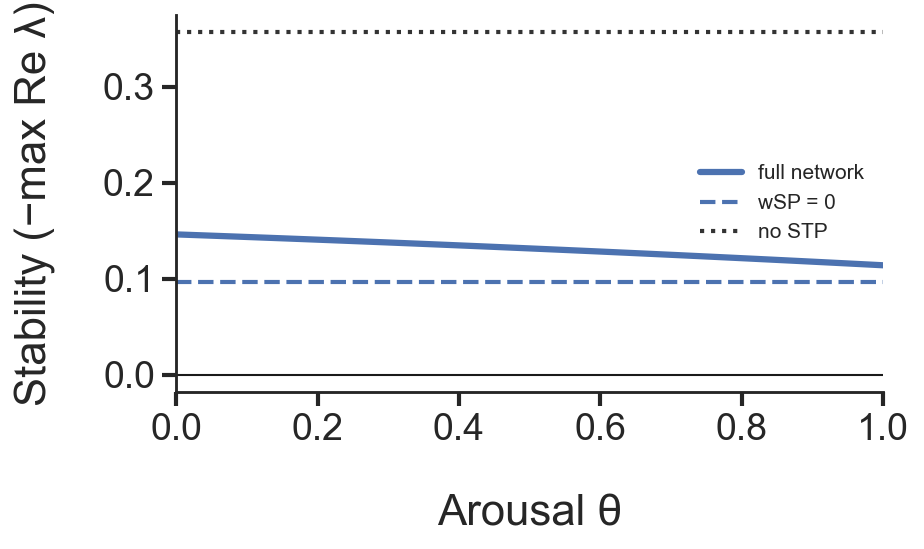

In [376]:
# stability along the arousal axis (same convention as the wSP-axis panels)
stab = -s_full["maxEV"]
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.plot(theta_vals, stab, color=stability_color)
ax.plot(theta_vals, -s_abl["maxEV"], color=stability_color, ls='--', lw=2)
# ax.plot(theta_vals, -s_ablV["maxEV"], color=colors['rV'], ls='--', lw=2)
ax.plot(theta_vals, -s_stat["maxEV"], color='0.2', ls=':', lw=2)
# ax.plot(theta_vals, -s_match["maxEV"], color='0.5', ls='-.', lw=2)
# ax.legend(['full network', 'wSP = 0', 'wSV = 0', 'static, no STP',
ax.legend(['full network', 'wSP = 0', 'no STP',
           'static, matched at θ=0'], fontsize=10, frameon=True,
          facecolor='white', edgecolor='none', framealpha=0.85)
ax.axhline(0, color='k', lw=1)
# ax.axhline(0.05, color='0.7', lw=1, ls=':')
# ax.text(0.995, 0.052, 'viability margin', color=stability_color, fontsize=10,
#         transform=ax.get_yaxis_transform(), ha='right', va='bottom')
# ax.set_ylim(-0.02, 0.2)
ax.set_xlabel('Arousal θ')
ax.set_ylabel('Stability (−max Re λ)')
# ax.set_title('stability along the arousal axis', fontsize=15, pad=10)
ax.set_xlim(0, 1)
# ax.set_ylim(-0.01, 0.4)
# ax.set_yticks([0.0, 0.2,0.4])
fig.tight_layout()
plt.savefig(saving_directory + "stability_theta.pdf")
plt.show()
# print(f"stability {stab[0]:.3f} (θ=0) -> {stab[-1]:.3f} (θ=1); "
#       f"peak {stab.max():.3f} at θ={theta_vals[np.argmax(stab)]:.2f}; "
#       f"worst {stab.min():.3f} at θ={theta_vals[np.argmin(stab)]:.2f}")

### Example: the same view just off the crossing band

`W_B` with its VIP→SST weight moved below (wSV = 0.2) and above (wSV = 0.4) its value 0.3 —
the crossing band is [0.245, 0.320]. Below: FF-dominant at every θ (ratio 0.48 → 0.72) and the
routed mix *falls* 0.85 → 0.52 — arousal hands the input to the permanently weaker channel.
Above: FB-dominant from rest (ratio 1.49 → 3.02); the mix rises 1.08 → 2.77 but nothing flips.
Only on the band does arousal transfer control; both examples are comfortably stable
(worst −0.34 / −0.16).


In [377]:
# # example: the same arousal-axis view with wSV shifted 0.1 below / above
# # the selected circuit's value (for W_RUN, wSV = 0.3 on the crossing band
# # [0.245, 0.320]: 0.2 sits below it, 0.4 above — viable to wSV ~ 0.48)
# fig, axes = plt.subplots(2, 2, figsize=(11, 7.5))
# for row, wsv_ex in enumerate((W_RUN[2, 3] - 0.1, W_RUN[2, 3] + 0.1)):
#     W_ex = W_RUN.copy()
#     W_ex[2, 3] = wsv_ex
#     s = VIP_circuit_neuromod(W_ex).sweep_arousal(theta_vals)

#     ax = axes[row, 0]
#     ax.plot(theta_vals, s["gain_FF"], color=color_FF)
#     ax.plot(theta_vals, s["gain_FB"], color=color_FB)
#     ax.plot(theta_vals, s["gain_mix"], color=color_mix, lw=3.5)
#     ax.text(0.03, s["gain_FF"][3], ' FF', color=color_FF, fontsize=13, va='bottom')
#     ax.text(0.03, s["gain_FB"][3], ' FB', color=color_FB, fontsize=13, va='top')
#     ax.text(0.72, s["gain_mix"][72], ' mix', color=color_mix, fontsize=13, va='bottom')
#     ax.set_ylabel(f'wSV = {wsv_ex:g}\nE gain')
#     if row == 1:
#         ax.set_xlabel('arousal θ')

#     ax = axes[row, 1]
#     ax.plot(theta_vals, s["ratio"], color='0.3')
#     ax.axhline(1, color='0.8', lw=1, ls='--')
#     ax.set_ylabel('gain_FB / gain_FF')
#     if row == 1:
#         ax.set_xlabel('arousal θ')

#     cr = np.where((s["ratio"][:-1] < 1) & (s["ratio"][1:] >= 1))[0]
#     print(f"wSV = {wsv_ex:g}: FF {s['gain_FF'][0]:.2f}->{s['gain_FF'][-1]:.2f} | "
#           f"FB {s['gain_FB'][0]:.2f}->{s['gain_FB'][-1]:.2f} | "
#           f"mix {s['gain_mix'][0]:.2f}->{s['gain_mix'][-1]:.2f} | "
#           f"ratio {s['ratio'][0]:.2f}->{s['ratio'][-1]:.2f} | "
#           f"{'crossing at ' + format(theta_vals[cr[0]], '.2f') if len(cr) and s['ratio'][0] < 1 else 'no crossing'} | "
#           f"maxEV worst {np.max(s['maxEV']):.2f}")
# axes[0, 0].set_title('gains and the routed mix', fontsize=15, pad=10)
# axes[0, 1].set_title('FB/FF ratio', fontsize=15, pad=10)
# fig.tight_layout()
# plt.show()


In [378]:
# fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharey=True)
# for ax, s_cmp, lbl, ls in [(axes[0], s_abl, 'wSP = 0', '--'),
#                            (axes[1], s_stat, 'static, no STP', ':')]:
#     ax.plot(theta_vals, s_full["maxEV"], color=stability_color, label='full network')
#     ax.plot(theta_vals, s_cmp["maxEV"], color=stability_color, ls=ls, label=lbl)
#     ax.legend(fontsize=12)
# axes[2].plot(theta_vals, s_full["maxEV"], color=stability_color)
# for ax, title in zip(axes, ['vs ablation', 'vs no STP', 'full network']):
#     ax.axhline(0, color='k', lw=1)
#     ax.set_xlabel('arousal θ')
#     ax.set_title(title, fontsize=15, pad=10)
# axes[0].set_ylabel('max Re λ')
# fig.tight_layout()
# plt.show()


## Gain and stability dependence on the PV rate set-point

In [398]:
np.linspace(0.1,1,5)

array([0.1  , 0.325, 0.55 , 0.775, 1.   ])

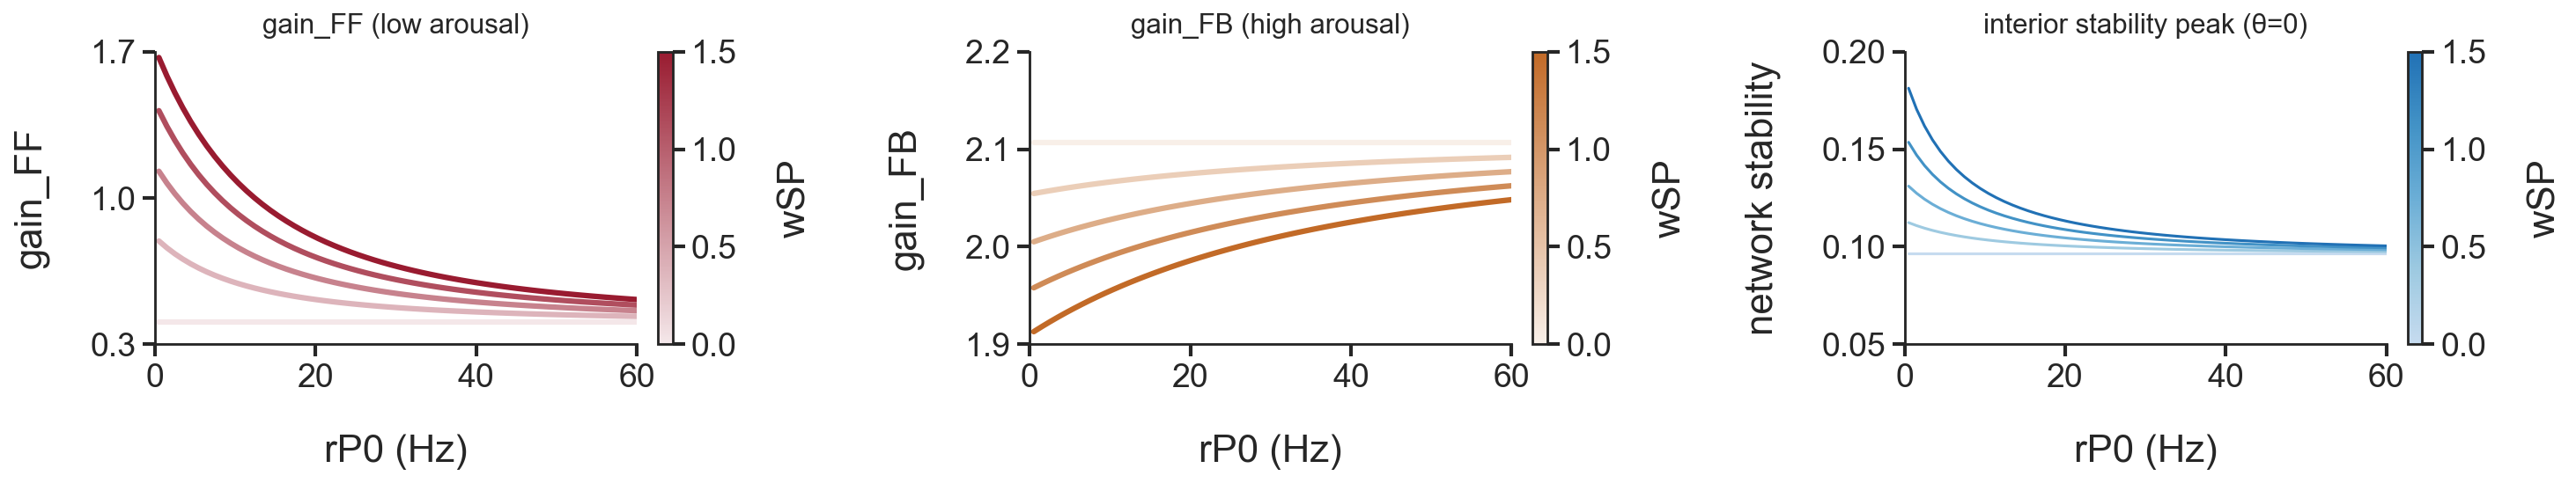

In [412]:
from matplotlib.colors import to_rgb

w_vals  = [0.0, 0.375, 0.75, 1.125, 1.5]
alphas  = [0.1, 0.325, 0.55, 0.775, 1.0]
W_MIN, W_MAX = 0.0, 1.5

def alpha_cmap(c, amin=0.1, amax=1.0):
    r, g, b = to_rgb(c)
    return LinearSegmentedColormap.from_list('a', [(r, g, b, amin), (r, g, b, amax)], N=256)

def add_wbar(fig, ax, cmap):
    sm = plt.cm.ScalarMappable(cmap=cmap, norm=plt.Normalize(W_MIN, W_MAX))
    fig.colorbar(sm, ax=ax, fraction=0.046, pad=0.04).set_label('wSP')

fig, axes = plt.subplots(1, 3, figsize=(20, 4))

for ax, theta, col, gi, title in [(axes[0], 0.0, color_FF, 0, 'gain_FF (low arousal)'),
                                  (axes[1], 1.0, color_FB, 1, 'gain_FB (high arousal)')]:
    for w, a in zip(w_vals, alphas):
        W = W_RUN.copy(); W[2, 1] = w
        g = np.array([gains_at(W, rp, theta) for rp in rP0_vals])
        ax.plot(rP0_vals, g[:, gi], color=col, alpha=a)
    ax.set_title(title, fontsize=15, pad=10)
    add_wbar(fig, ax, alpha_cmap(col))

for w in np.linspace(W_MIN, W_MAX, 5):
    axes[2].plot(rP0_vals, stability_curve(w, rP0_vals), color=cmap_w(w / W_MAX), lw=1.5)
add_wbar(fig, axes[2], cmap_w)
axes[2].set_title('interior stability peak (θ=0)', fontsize=15, pad=10)

axes[0].set_ylabel('gain_FF'); axes[1].set_ylabel('gain_FB')
axes[2].set_ylabel('network stability')
for ax in axes:
    ax.set_xlabel('rP0 (Hz)')
    ax.set_xlim(rP0_vals[0], rP0_vals[-1])
    ax.set_xticks([0,20,40,60])
axes[0].set_ylim(0.3, 1.7); axes[1].set_ylim(1.9, 2.2); axes[2].set_ylim(0.05, 0.2)
axes[0].set_yticks([0.3, 1.0, 1.7]); axes[1].set_yticks([1.9, 2.0, 2.1,2.2]); axes[2].set_yticks([0.05, 0.1, 0.15,0.2])
fig.tight_layout()
plt.savefig(saving_directory + "gains_stability_rP0_wSP.pdf")
plt.show()

### The routed mix vs the PV set-point, as a function of $w_{SP}$

Both panels share the same construction (wSP ramp from 0 to 1, `W_RUN`'s own weight in
bold): the left shows the E gain to the arousal-routed stimulus at mid-arousal
(θ = 0.5), the right the θ = 0 stability curve from the cell above. The parallel is the
point — for this circuit the synapse lifts **both** curves at every PV set-point, with
the same shape: the benefit is largest at low rates (+0.30 on the mixed gain at 1 Hz,
+0.25 at 5 Hz over the flat wSP = 0 baseline of 1.256) and decays as the depression
saturates (+0.05 at 60 Hz), exactly mirroring the stability benefit. The wSP = 0
baseline is rate-independent in both panels — without the synapse the PV set-point
enters neither the routed gain nor the stability margin.


In [381]:
# # the arousal-routed E gain vs the PV rate set-point as a function of wSP,
# # next to the stability curve built exactly as in the cell above
# def mix_curve(w_val, rates, th_v=0.5):
#     out = np.full(len(rates), np.nan)
#     W = W_RUN.copy()
#     W[2, 1] = w_val
#     for k, rp in enumerate(rates):
#         c = VIP_circuit_neuromod(W, rP0=rp, theta=th_v)
#         res = c._compute_block("weights", c.rE0, c.rP0, c.rS0, c.rV0)
#         if not res["singular"]:
#             out[k] = (1 - th_v) * res["gain_FF"] + th_v * res["gain_FB"]
#     return out

# fig, axes = plt.subplots(1, 2, figsize=(12, 4))
# ax = axes[0]
# for w in np.linspace(0.0, 1.0, 5):
#     ax.plot(rP0_vals, mix_curve(w, rP0_vals), color=cmap_w(w), lw=1.5)
# ax.plot(rP0_vals, mix_curve(W_RUN[2, 1], rP0_vals), color='k', lw=3,
#         label=f"W_RUN (wSP = {W_RUN[2, 1]:.1f})")
# sm = plt.cm.ScalarMappable(cmap=cmap_w, norm=plt.Normalize(0, 1))
# cbar = fig.colorbar(sm, ax=ax, fraction=0.046, pad=0.04)
# cbar.set_label('wSP')
# ax.set_xlabel('rP0 (Hz)')
# ax.set_ylabel('gain_mix (θ = 0.5)')
# ax.legend(fontsize=12)
# ax.set_title('routed E gain vs the PV set-point', fontsize=15, pad=10)

# ax = axes[1]
# for w in np.linspace(0.0, 1.0, 5):
#     ax.plot(rP0_vals, stability_curve(w, rP0_vals), color=cmap_w(w), lw=1.5)
# ax.plot(rP0_vals, stability_curve(W_RUN[2, 1], rP0_vals), color='k', lw=3,
#         label=f"W_RUN (wSP = {W_RUN[2, 1]:.1f})")
# sm = plt.cm.ScalarMappable(cmap=cmap_w, norm=plt.Normalize(0, 1))
# cbar = fig.colorbar(sm, ax=ax, fraction=0.046, pad=0.04)
# cbar.set_label('wSP')
# ax.set_xlabel('rP0 (Hz)')
# ax.set_ylabel('network stability')
# ax.legend(fontsize=12)
# ax.set_title('stability vs the PV set-point (θ=0)', fontsize=15, pad=10)
# fig.tight_layout()
# plt.show()

# m0 = mix_curve(0.0, rP0_vals)
# mB = mix_curve(W_RUN[2, 1], rP0_vals)
# for rp in (1.0, 5.0, 12.0, 60.0):
#     k = int(np.argmin(np.abs(rP0_vals - rp)))
#     print(f"synapse benefit on gain_mix(0.5) at rP0 = {rp:g} Hz: "
#           f"{mB[k] - m0[k]:+.3f} ({mB[k]:.3f} vs {m0[k]:.3f} ablated)")


## Plot supp - Robustness: parameter dependence (tornado)

One-at-a-time margins around the `W_RUN` defaults (weights, ACh depth, τ_SP, set-points),
marched until each result first fails.

Operational definitions (criteria updated 2026-08-19 to the plot-1/2/3 conditions;
probed only if they hold at the baseline circuit):
- **R2 mix benefit** (plot 3, redefined) — the routed mix stays on its baseline side of the
  wSP = 0 partner at every θ (for the current W_RUN: mix > ablated mix everywhere).
- **R3 peak** — stability vs rP ∈ [0.5, 60] Hz at θ=0: interior argmax in 2–50 Hz, prominence
  ≥ 0.02, stable across the sweep (fails at the current W_RUN's baseline → skipped).
- **R4 viability** — max Re λ ≤ −0.05 for all θ.
- **R5 ablation** (plot 1) — gain_FF with wSP = 0 is lower at every θ.
- **R6 class** (plot 2) — the determinant slope d₁ = (w_EE−1)w_PS − w_ES·w_PE keeps its
  baseline sign (here −1: the static synapse outgains the depressed one).
- R1 (synaptic signatures) is robust by construction (monotone in U).

The collapsed tornado below shows, per parameter, the joint interval where **all** probed
results hold (value/default, log scale; arrows = censored), tightest-first; the table gives
per-criterion break points.

Headlines for the current W_RUN: the entire neuromodulation arm — U_SP_base, U_SP_high,
τ_SP, rP0, rV0 — is **censored for every criterion**: the redefined results are
θ-independent anatomical sign bits, so ACh depth and set-points cannot break them (the old
rP0 ≲ 8 Hz constraint was an artifact of the crossing-based R2). All binding constraints
are anatomical, and R2 and R6 break at the **same** points on d₁'s four weights — the
θ = 1 endpoint of the mix comparison *is* the d₁ law: w_EE ≤ 1.37 (the thinnest headroom,
+5%), w_PS ≤ 0.89, w_ES ≥ 1.05, and w_PE ≥ 0.18 — just 0.02 below its default, matching
d₁ = −0.03 at baseline. R4 adds the wSV ≤ 0.8 and wVS ≤ 2.3 caps; wSP itself is censored
everywhere except the degenerate wSP = 0 point where the comparisons vanish by definition.

In [339]:
# push-till-it-breaks margins (runs ~1-2 min); criteria updated 2026-08-19:
# R2 = the plot-3 condition (mix vs its wSP = 0 partner, baseline direction),
# R6 = the plot-2 condition (sign of d1 = (wEE-1)wPS - wES*wPE preserved)
import pandas as pd

THETA_R = np.linspace(0, 1, 11)
RATES_R = np.linspace(0.5, 60, 31)

W_POS = {"wEE": (0, 0), "wEP": (0, 1), "wES": (0, 2),
         "wPE": (1, 0), "wPP": (1, 1), "wPS": (1, 2),
         "wSE": (2, 0), "wSP": (2, 1), "wSV": (2, 3),
         "wVE": (3, 0), "wVP": (3, 1), "wVS": (3, 2)}

PARAMS_R = {name: (W_RUN[pos], 0.0, 3.0) for name, pos in W_POS.items()}
PARAMS_R.update({
    "U_SP_base": (0.5, 0.05, 1.0),
    "U_SP_high": (0.15, 0.01, 1.0),
    "tau_SP":    (0.1, 0.01, 0.6),
    "rP0":       (5.0, 0.5, 30.0),
    "rV0":       (2.0, 0.1, 15.0),
})

def build_circuit(name, val, theta=0.0):
    W = W_RUN.copy()
    kwargs = {}
    if name in W_POS:
        W[W_POS[name]] = val
    elif name in ("rP0", "rV0"):
        kwargs[name] = val
    c = VIP_circuit_neuromod(W, theta=theta, **kwargs)
    if name in ("U_SP_base", "U_SP_high", "tau_SP"):
        setattr(c, name, val)
    c.set_arousal(theta)
    return c

def evaluate_results(name, val):
    c = build_circuit(name, val)
    s = c.sweep_arousal(THETA_R)
    finite = not np.any(np.isnan(s["maxEV"]))
    r4 = finite and np.max(s["maxEV"]) <= -0.05

    # ablated partner (wSP = 0), shared by R2 and R5
    c5 = build_circuit(name, val)
    c5._assign_weights({"wSP": 0.0})
    s5 = c5.sweep_arousal(THETA_R)
    finite5 = finite and not np.any(np.isnan(s5["maxEV"]))

    # R2 (redefined 2026-08-19, the plot-3 condition): the routed mix stays on
    # its baseline side of the wSP = 0 partner at EVERY theta
    r2 = finite5 and bool(np.all((s["gain_mix"] - s5["gain_mix"]) * MIX_DIR > 0))

    # R5 (the plot-1 condition): gain_FF with wSP = 0 is lower at every theta
    r5 = finite5 and bool(np.all(s5["gain_FF"] < s["gain_FF"]))

    # R6 (the plot-2 condition): the determinant slope d1 keeps its baseline
    # sign — the depressed-vs-static gain_FB class is intact
    r6 = bool(np.sign((c.wEE - 1) * c.wPS - c.wES * c.wPE) == D1_SIGN)

    c = build_circuit(name, val)
    stab = np.full(len(RATES_R), np.nan)
    for k, r in enumerate(RATES_R):
        c.rP0 = r
        res = c._compute_block("weights", c.rE0, c.rP0, c.rS0, c.rV0)
        if not res["singular"]:
            stab[k] = -res["max_ev_real"]
    if np.any(np.isnan(stab)) or np.min(stab) < 0.05:
        r3 = False
    else:
        i = int(np.argmax(stab))
        prom = stab[i] - max(stab[0], stab[-1])
        r3 = (0 < i < len(RATES_R) - 1) and prom >= 0.02 and 2 < RATES_R[i] < 50
    return {"R2": r2, "R3": r3, "R4": r4, "R5": r5, "R6": r6}

# baseline directions for the class criteria (fixed once, on W_RUN itself)
_cb = build_circuit("wEE", PARAMS_R["wEE"][0])
_sb = _cb.sweep_arousal(THETA_R)
_cb0 = build_circuit("wEE", PARAMS_R["wEE"][0])
_cb0._assign_weights({"wSP": 0.0})
_sb0 = _cb0.sweep_arousal(THETA_R)
MIX_DIR = (1 if np.all(_sb["gain_mix"] > _sb0["gain_mix"])
           else -1 if np.all(_sb["gain_mix"] < _sb0["gain_mix"]) else 0)
D1_SIGN = np.sign((_cb.wEE - 1) * _cb.wPS - _cb.wES * _cb.wPE)
print(f"baseline classes: mix vs ablation direction {MIX_DIR:+d} "
      f"(0 = curves cross at baseline -> R2 skipped); sign(d1) = {D1_SIGN:+.0f}")

base = evaluate_results("wEE", PARAMS_R["wEE"][0])   # the unmodified circuit
CRITS = [c for c in ["R2", "R3", "R4", "R5", "R6"] if base[c]]
absent = [c for c in ["R2", "R3", "R4", "R5", "R6"] if not base[c]]
if absent:
    print(f"criteria failing at the baseline circuit, skipped: {absent}")

breaks_num = {}
rows = []
for name, (default, lo, hi) in PARAMS_R.items():
    breaks_num[name] = {}
    row = {"parameter": name, "default": default}
    for crit in CRITS:
        lo_break = hi_break = None
        for v in np.linspace(default, lo, 25)[1:]:
            if not evaluate_results(name, v)[crit]:
                lo_break = v
                break
        for v in np.linspace(default, hi, 25)[1:]:
            if not evaluate_results(name, v)[crit]:
                hi_break = v
                break
        breaks_num[name][crit] = (lo_break, hi_break)
        row[f"{crit} low"] = f"<{lo:g}" if lo_break is None else f"{lo_break:.2f}"
        row[f"{crit} high"] = f">{hi:g}" if hi_break is None else f"{hi_break:.2f}"
    rows.append(row)

df_robust = pd.DataFrame(rows).set_index("parameter")
df_robust

baseline classes: mix vs ablation direction +0 (0 = curves cross at baseline -> R2 skipped); sign(d1) = +1
criteria failing at the baseline circuit, skipped: ['R2', 'R3']


,default,R4 low,R4 high,R5 low,R5 high,R6 low,R6 high
parameter,,,,,,,
wEE,1.30,<0,1.44,<0,1.51,1.14,>3
wEP,0.70,<0,1.08,<0,1.37,<0,>3
wES,1.20,1.00,>3,1.00,>3,<0,2.17
wPE,0.10,<0,>3,<0,>3,<0,0.22
wPP,0.10,<0,>3,<0,>3,<0,>3
wPS,0.70,<0,0.99,<0,0.89,0.38,>3
wSE,1.20,1.00,>3,0.90,>3,<0,>3
wSP,1.50,<0,>3,0.00,>3,<0,>3
wSV,0.50,<0,0.71,<0,0.71,<0,>3


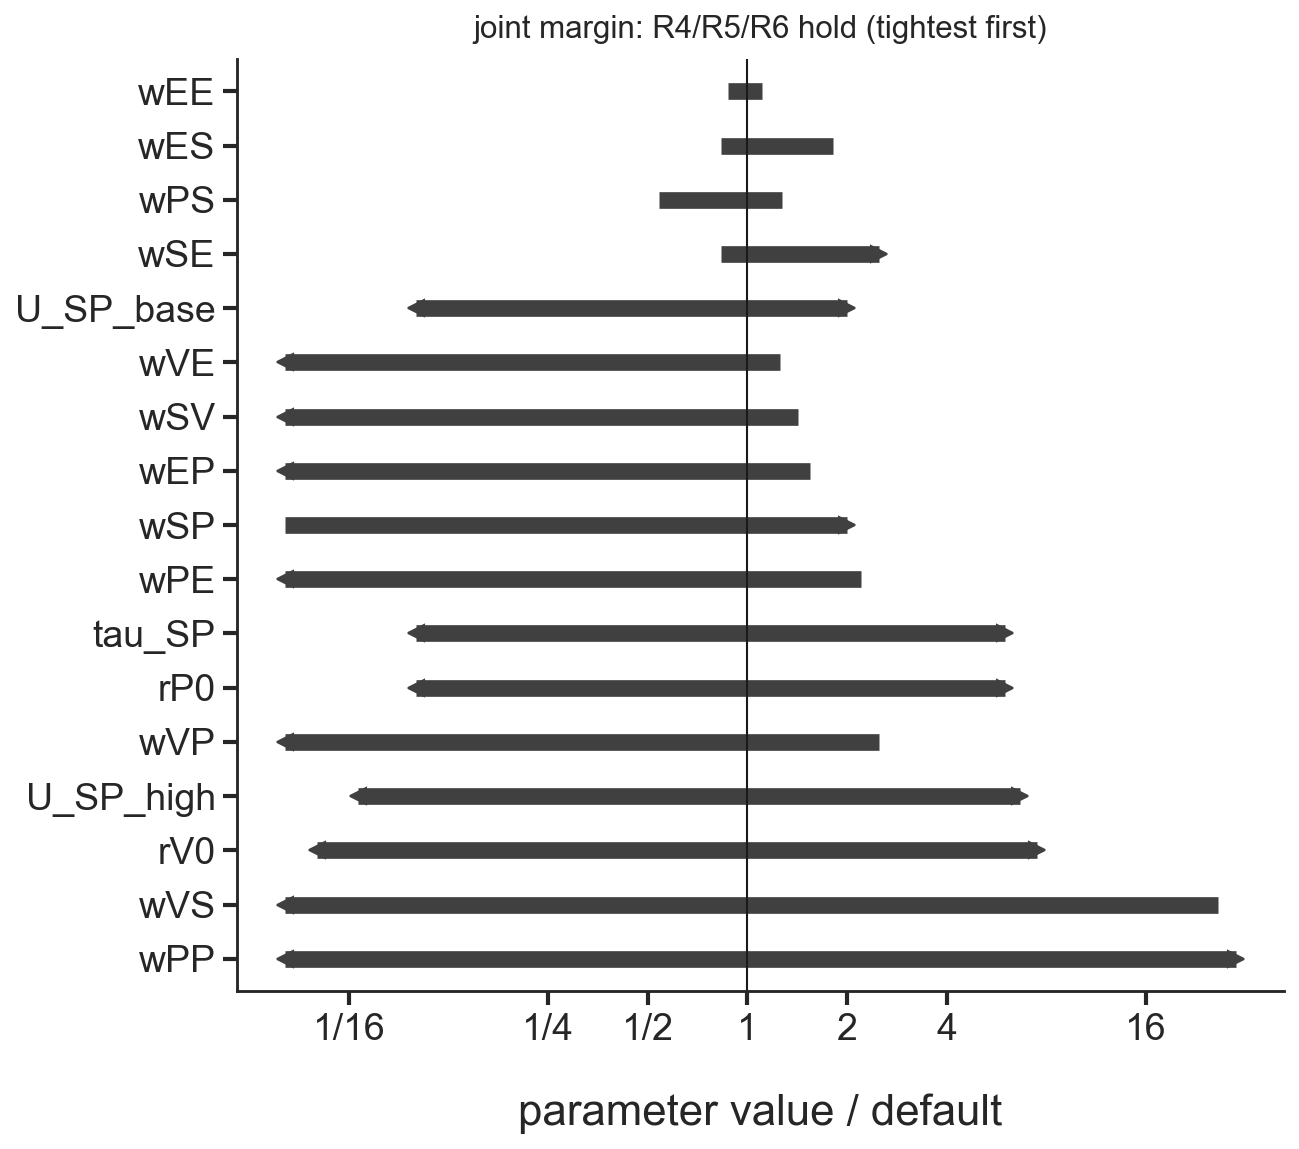

In [340]:
# collapsed tornado: joint interval where ALL results hold (tightest margins first)
names_r = list(PARAMS_R.keys())
joint = {}
for name in names_r:
    default, lo_b, hi_b = PARAMS_R[name]
    lo_edges, hi_edges = [], []
    lo_cens, hi_cens = True, True
    for crit in CRITS:
        lo_v, hi_v = breaks_num[name][crit]
        lo_edges.append(lo_b if lo_v is None else lo_v)
        hi_edges.append(hi_b if hi_v is None else hi_v)
        lo_cens &= lo_v is None
        hi_cens &= hi_v is None
    joint[name] = (max(lo_edges), min(hi_edges), lo_cens, hi_cens)

def rel_interval(name):
    default = PARAMS_R[name][0]
    lo_e, hi_e = joint[name][0], joint[name][1]
    x0 = max(lo_e / default, 0.04)
    return x0, hi_e / default

order = sorted(names_r, key=lambda n: np.log(rel_interval(n)[1] / rel_interval(n)[0]))

fig, ax = plt.subplots(figsize=(9, 8))
for yi, name in enumerate(order):
    x0, x1 = rel_interval(name)
    lo_c, hi_c = joint[name][2], joint[name][3]
    ax.plot([x0, x1], [yi, yi], color='0.25', lw=8, solid_capstyle='butt')
    if lo_c:
        ax.plot(x0, yi, marker='<', color='0.25', ms=8)
    if hi_c:
        ax.plot(x1, yi, marker='>', color='0.25', ms=8)
ax.axvline(1, color='k', lw=1)
ax.set_yticks(range(len(order)), order)
ax.set_xscale('log', base=2)
ax.set_xticks([0.0625, 0.25, 0.5, 1, 2, 4, 16],
              ['1/16', '1/4', '1/2', '1', '2', '4', '16'])
ax.set_xlabel('parameter value / default')
ax.set_ylim(-0.6, len(order) - 0.4)
ax.invert_yaxis()
ax.set_title(f'joint margin: {"/".join(CRITS)} hold (tightest first)', fontsize=15, pad=10)
fig.tight_layout()
plt.savefig(saving_directory + "robustness_joint_tornado.pdf")
plt.show()

# How abundant is each plotted result in the 26.2M grid?

Each cell below takes one of the four headline plots and asks how common its behavior is
across the full **uniform-values** ISN grid (26,214,400 configurations,
`full_results_arousal_ff_fb_isn_uniform.pkl`: every weight on {0.1, 0.7, 1.2, 1.8},
wEE on {1.1, 1.3, 1.5, 1.8}, wSP/wSV with the extra 0), and why — the closed-form
structure at power = 1 turns most of the questions into exact statements. Numbers from
the original ISN grid (wSP/wSV on {0, 0.4, 0.9, 1.3, 1.8}) are quoted in parentheses
where they differ — the agreement between the two grids separates structural results
from grid-composition artifacts. All stability numbers are the quasi-static 4×4 rate
Jacobian (the grid's `lam` columns).

## Plot 1 — does $w_{SP}$ increase the gain? Does it increase stability?

**Gain: yes for ~85% of circuits — and the monotone shape is a theorem.** At power = 1
the synapse enters the linear theory only through the effective coupling
$k = c_{SP} w_{SP}$, and $gain_{FF}(k) = N_{FF}(k)/D(k)$ with **both $N_{FF}$ and $D$
linear in $k$**. A ratio of linear functions is monotone on any interval free of det
zeros — and a det zero implies instability — so on any viable stretch of the $w_{SP}$
axis the gain curve *cannot* change direction. "Does $w_{SP}$ increase the gain" is
therefore a single θ-independent sign bit per circuit: rising in 84.7% of 3.05M
positive-gain circuits paired with their exact $w_{SP}=0$ partner (83.3% on the
original grid — robust), and 98% of full-axis-viable families are strictly monotone
across the five grid points, confirming the theorem at float16 resolution.

**The sign bit in closed form.** For a ratio of linears the derivative's numerator is
the Wronskian of $N_{FF}$ and $D$ — a $k$-independent **constant**, which is the
strongest form of the monotonicity statement (the sign cannot change anywhere on the
axis, at any θ):

$$\frac{\partial\, gain_{FF}}{\partial k} \;=\; \frac{\mathcal{W}}{D(k)^2}, \qquad
\mathcal{W} \;=\; \underbrace{(w_{ES}-w_{PS})}_{\partial N_{FF}/\partial k}\,D
\;-\; N_{FF}\,\underbrace{\left[(w_{EE}-1)\,w_{PS}-w_{ES}\,w_{PE}\right]}_{\partial D/\partial k}
\;=\; \text{const},$$

so, dividing by $D > 0$ on the stable branch:

$$w_{SP} \text{ raises } gain_{FF} \iff (w_{ES}-w_{PS}) \;>\; gain_{FF}\cdot\left[(w_{EE}-1)\,w_{PS}-w_{ES}\,w_{PE}\right].$$

The two derivatives are the project's two master quantities. $\partial N_{FF}/\partial k
= w_{ES}-w_{PS}$ is the SST-routing competition — the synapse converts PV drive into
SST suppression, and SST's net effect on E is direct inhibition ($w_{ES}$) minus
PV-mediated disinhibition ($w_{PS}$) — the *same* difference that governs the plot-3
ratio law (ratio $= N_{FB}/N_{FF}$ with $N_{FB}$ fixed). $\partial D/\partial k$ is
plot-2's criticality slope, here weighted by the circuit's own gain: for the $d_1<0$
majority, more coupling also shrinks the determinant, so the numerator routing and the
criticality inflation usually pull together — which is why "gain up" (85%) is more
common than either term alone. Verified: the chord-Wronskian identity holds to 1e-9 on
W_RUN, and the criterion reproduces the measured sign bit in 99.997% of the 2.93M
clear-change pairs (residual = float16 evaluation near the criterion's zero, where
near-critical $D^2$ amplifies rounding).

**Stability: no — the rising class is a ~28% minority.** Stability has no
ratio-of-linears form, and its shape along $w_{SP}$ is a genuine circuit property: the
majority of full-axis-viable families *lose* stability along $w_{SP}$ (56.6%; 60.0% on
the original grid), monotone rise holds 27.9% (26.0%), and an interior peak 14.3%
(12.8%). The class shares barely move between the two grids, so the split is
structural, not an artifact of the sampled values. The coarse 5-point axis can hide
narrow peaks, so the mono shares are upper bounds (an 81-point sweep on a 10k sample of
the original grid gave 61/20/18).

gain_FF(own wSP) > gain_FF(wSP=0): 84.7% of 3.05M positive-gain circuits vs their ablation partner — one theta-independent sign bit per circuit
families viable across the whole wSP axis at theta=0: 1,865,589 of 5,242,880
gain_FF strictly monotone along the axis there: 97.82% (rising 69.8%, falling 28.0%; ties/float16 wiggles make up the rest)
stability (-max Re lam) vs wSP, shape classes among full-axis-viable families:
  theta=0: mono up 27.9%, mono down 56.6%, interior peak 14.3%, interior valley 0.1%, flat/multi 1.1%
  theta=1: mono up 33.5%, mono down 59.0%, interior peak 6.1%, interior valley 0.1%, flat/multi 1.3%
W_RUN: gain_FF rising on [0,2]: True; stability monotone rising: True (the mono-up class holds 28% of families)
ratio-of-linears check (W_RUN): gain_FF at U_SP=0.3 reconstructed from the two stored states = 1.098885, direct = 1.098885


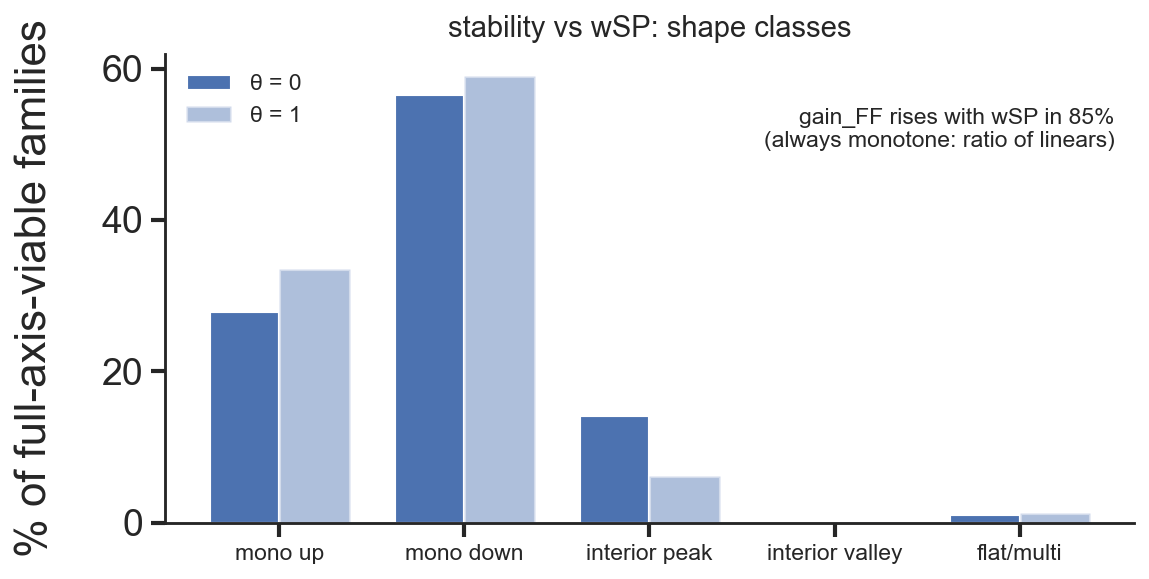

In [325]:
# Plot 1 in the grid: the gain_FF direction is a single sign bit (gain_FF is a
# ratio of linears in k = cSP*wSP, hence monotone on any stable stretch of the
# wSP axis); the stability direction is a genuine shape split over the 5-point
# wSP axis. All lam values are the quasi-static 4x4 rate Jacobian.
import pickle as _pkl
if "_du" not in globals():
    if not LOAD:
        raise RuntimeError("LOAD is False: run the grid simulations first "
                           "(run_uniform_grid.sh + reassemble_uniform.py, see "
                           "README) and point GRID_PATH at the resulting "
                           "full_results_arousal_ff_fb_isn_uniform.pkl")
    with open(GRID_PATH, "rb") as _f:
        _pku = _pkl.load(_f)
    _ciu = {c: i for i, c in enumerate(_pku["columns"])}
    _du = _pku["data"].astype(np.float32)
_dims = (4, 4, 4, 4, 4, 4, 4, 5, 5, 4, 4, 4)   # param_order axes; wSP is axis 7

def _wsp_view(arr):
    # (families, 5): one row per fixed choice of the other 11 weights,
    # columns = the wSP axis {0, 0.1, 0.7, 1.2, 1.8}
    return np.moveaxis(arr.reshape(_dims), 7, 11).reshape(-1, 5)

lam_lo, lam_hi = _du[:, _ciu["lam_low"]], _du[:, _ciu["lam_high"]]
stable = np.isfinite(lam_lo) & np.isfinite(lam_hi) & (lam_lo <= -0.05) & (lam_hi <= -0.05)
dom = (stable & (_du[:, _ciu["gain_FF_low"]] > 0) & (_du[:, _ciu["gain_FF_high"]] > 0)
       & (_du[:, _ciu["gain_FB_low"]] > 0) & (_du[:, _ciu["gain_FB_high"]] > 0))
lamF0, lamF1 = _wsp_view(lam_lo), _wsp_view(lam_hi)
gFF0 = _wsp_view(_du[:, _ciu["gain_FF_low"]])

# (a) the sign bit: every functional circuit against its exact wSP = 0 partner
# (same pairing and population as the earlier paired-view cell)
mpair = _wsp_view(dom) & np.isfinite(gFF0[:, :1]) & (gFF0[:, :1] > 0)
mpair[:, 0] = False
frac_rise = (gFF0 > gFF0[:, :1])[mpair].mean()
print(f"gain_FF(own wSP) > gain_FF(wSP=0): {frac_rise:.1%} of {mpair.sum()/1e6:.2f}M "
      f"positive-gain circuits vs their ablation partner — one theta-independent "
      f"sign bit per circuit")

# (b) the whole axis: families viable at every wSP point (theta = 0, margin -0.05)
ax_ok0 = (np.isfinite(lamF0) & (lamF0 <= -0.05)).all(axis=1)
dg = np.diff(gFF0[ax_ok0], axis=1)
mono_up_g, mono_dn_g = np.all(dg > 0, axis=1), np.all(dg < 0, axis=1)
print(f"families viable across the whole wSP axis at theta=0: {ax_ok0.sum():,} of {len(ax_ok0):,}")
print(f"gain_FF strictly monotone along the axis there: {(mono_up_g | mono_dn_g).mean():.2%} "
      f"(rising {mono_up_g.mean():.1%}, falling {mono_dn_g.mean():.1%}; ties/float16 wiggles make up the rest)")

# (c) stability shape classes over the same axis
def _shape_classes(lamF, ok):
    sgn = np.sign(np.diff(-lamF[ok], axis=1))
    up = np.all(sgn >= 0, axis=1) & (sgn.max(axis=1) > 0)
    dn = np.all(sgn <= 0, axis=1) & (sgn.min(axis=1) < 0)
    pk = np.zeros(len(sgn), bool)
    vl = np.zeros(len(sgn), bool)
    for j in range(1, sgn.shape[1]):
        pk |= (np.all(sgn[:, :j] >= 0, axis=1) & (sgn[:, :j].max(axis=1) > 0)
               & np.all(sgn[:, j:] <= 0, axis=1) & (sgn[:, j:].min(axis=1) < 0))
        vl |= (np.all(sgn[:, :j] <= 0, axis=1) & (sgn[:, :j].min(axis=1) < 0)
               & np.all(sgn[:, j:] >= 0, axis=1) & (sgn[:, j:].max(axis=1) > 0))
    pk &= ~(up | dn)
    vl &= ~(up | dn)
    return np.array([f.mean() for f in (up, dn, pk, vl, ~(up | dn | pk | vl))])

ax_ok1 = (np.isfinite(lamF1) & (lamF1 <= -0.05)).all(axis=1)
cls0, cls1 = _shape_classes(lamF0, ax_ok0), _shape_classes(lamF1, ax_ok1)
cls_names = ["mono up", "mono down", "interior peak", "interior valley", "flat/multi"]
print("stability (-max Re lam) vs wSP, shape classes among full-axis-viable families:")
print("  theta=0: " + ", ".join(f"{n} {f:.1%}" for n, f in zip(cls_names, cls0)))
print("  theta=1: " + ", ".join(f"{n} {f:.1%}" for n, f in zip(cls_names, cls1)))

# W_RUN itself, on the fine axis of Plot 1
wsp_chk = np.linspace(0.0, 2.0, 41)
r_run = VIP_circuit_neuromod(W_RUN, theta=0.0).calculate_linear_theory_general(
    mode="weights", grid_search=False, w1_name="wSP", w1_vals=wsp_chk)
print(f"W_RUN: gain_FF rising on [0,2]: {bool(np.all(np.diff(r_run['gain_FF']) > 0))}; "
      f"stability monotone rising: {bool(np.all(np.diff(-r_run['maxEV']) > 0))} "
      f"(the mono-up class holds {cls0[0]:.0%} of families)")

# closed-form check: gain_FF = N_FF(k)/D(k), both linear in k — reconstruct from the
# two arousal ends and predict a third synaptic state exactly (power = 1)
_c = VIP_circuit_neuromod(W_RUN)
_cof = lambda U: U / (1 + U * _c.rP0 * _c.tau_SP)**2

def _gains_at_U(U):
    _c.U_SP = U
    _res = _c._compute_block("weights", _c.rE0, _c.rP0, _c.rS0, _c.rV0)
    return _res["gain_FF"], _res["gain_FB"]

(gF_lo, gB_lo), (gF_hi, gB_hi) = _gains_at_U(0.5), _gains_at_U(0.15)
_bmid = (_cof(0.3) - _cof(0.5)) / (_cof(0.15) - _cof(0.5))
_Dh = gB_lo / gB_hi                                   # D(k_lo) := 1; N_FB is k-free
gF_pred = (gF_lo + (gF_hi * _Dh - gF_lo) * _bmid) / (1 + (_Dh - 1) * _bmid)
gF_true = _gains_at_U(0.3)[0]
assert abs(gF_pred - gF_true) < 1e-9, (gF_pred, gF_true)
print(f"ratio-of-linears check (W_RUN): gain_FF at U_SP=0.3 reconstructed from the two "
      f"stored states = {gF_pred:.6f}, direct = {gF_true:.6f}")

fig, ax = plt.subplots(figsize=(8, 4.2))
xb = np.arange(len(cls_names))
ax.bar(xb - 0.19, 100 * cls0, 0.38, color=stability_color, label='θ = 0')
ax.bar(xb + 0.19, 100 * cls1, 0.38, color=stability_color, alpha=0.45, label='θ = 1')
ax.set_xticks(xb, cls_names, fontsize=11)
ax.set_ylabel('% of full-axis-viable families')
ax.set_title('stability vs wSP: shape classes', fontsize=14, pad=8)
ax.text(0.98, 0.80, f"gain_FF rises with wSP in {frac_rise:.0%}\n(always monotone: ratio of linears)",
        transform=ax.transAxes, ha='right', fontsize=11, color='0.15')
ax.legend(fontsize=11)
fig.tight_layout()
plt.show()

del lamF0, lamF1, gFF0, mpair, dg

## Plot 2 — is $gain_{FB}$ always bigger with the depressing synapse than without?

**No — it is a selected ~11% minority class, on both grids.** The structural fact: the
FB-gain numerator $N_{FB}$ contains no $w_{SP}$ term (expanding the E←V cofactor along
the VIP column eliminates the SST row), so the PV→SST synapse moves
$gain_{FB} = N_{FB}/D(k)$ **only through the determinant**, which is linear in
$k = c_{SP} w_{SP}$. The static (no-STP) control is the same circuit at $k = w_{SP}$,
so "depressed beats static" ⟺ $D$ grows with $k$ (det slope $p > 0$) — one sign bit,
and the same bit as "$gain_{FB}$ rises under ACh".

**The condition in closed form.** Since $k$ occupies a single matrix entry (S←P), the
det slope is that entry's cofactor — the two ways SST closes a loop back onto PV:

$$\frac{\partial \det}{\partial k} \;=\; (w_{EE}-1)\,w_{PS} \;-\; w_{ES}\,w_{PE},
\qquad\text{depression boosts } gain_{FB} \iff (w_{EE}-1)\,w_{PS} > w_{ES}\,w_{PE}.$$

The $-w_{ES}w_{PE}$ term is the disinhibition loop PV→SST→E→PV — positive feedback, so
more coupling *shrinks* the determinant (moves the circuit toward criticality, which
inflates $1/\det$ and with it the response to every input, FB included). The
$+(w_{EE}-1)w_{PS}$ term is the PV⇄SST mutual-inhibition 2-cycle weighted by the
unstable E core (positive only because the grid is ISN): tightening it *contains* the
E instability and grows the determinant. Verified on the grid: the measured sign bit
"depressed > static" equals sign$\left[(w_{EE}-1)w_{PS} - w_{ES}w_{PE}\right]$ in
100.0000% of the 2.93M circuits with a resolvable FB change (the rest are float16 ties
at slope ≈ 0).

**How this condition overlaps with plot 1's.** In the plane $x = w_{ES}-w_{PS}$
(routing term), $y = gain_{FF}\cdot d_1$ (gain-weighted criticality slope, with
$d_1 = \partial D/\partial k$ above), plot 2 is the half-plane $y > 0$ and plot 1 is
$x > y$; both hold only on the wedge $x > y > 0$. Consequences (all grid-verified):
(i) the conditions are strongly *anti*-correlated — for the $d_1<0$ majority the same
shrinking determinant that hands the static synapse its FB advantage also inflates
$gain_{FF}$, so P(FF rises | $d_1<0$) = 91.8% vs 30.0% in the $d_1>0$ class; jointly:
FF↑ & static-wins 81.8% (the modal combo), FF↑ & FB-boosted 3.3% (the featured wedge),
FF↓ 7.6/7.3%. (ii) The wedge is a **nesting theorem**: both conditions together force
$w_{ES} > w_{PS}$, hence (ratio law) the FB/FF ratio *rises* under arousal — 0
counterexamples in 102,535 such circuits; the wedge is also gain-limited, since the
criticality cost $y$ scales with the circuit's own gain while the routing benefit $x$
is anatomical. (iii) On the slice $w_{ES}=w_{PS}$ the two conditions are exactly
complementary — "$w_{SP}$ raises the FF gain" ⟺ "depression taxes the FB gain"
(94.6% measured on 1.11M rows; the residual is the degenerate $d_1=0$ coincidences
where both changes vanish).

Because $D$ is linear, each grid circuit's static partner is *exactly* reconstructible
from the two stored arousal conditions (the interpolation weight
$(1 - c_{lo})/(c_{hi} - c_{lo}) = -3.58$ is even $w_{SP}$-free). On the 3.14M
positive-gain circuits with $w_{SP} > 0$: the static control has the **larger** FB gain
in 73.4% (71.0% on the original grid) — the disinhibition loop usually wins, so the
static synapse, carrying 3× the coupling, sits closer to the det zero and rides the
higher $1/\det$; depression is a retreat from criticality that trades gain for det
margin. The static control is det-certified unstable in 15.7% (19.0%) — the same $b<0$
line continued past the zero — and loses to depression in only **10.9%** (10.0%): the
class shares are grid-robust. The exact class geometry holds again with zero
counter-examples: $p > 0$ circuits can never have a det-dead static control, so their
static controls either survive or die by oscillation with det > 0 — a failure mode the
two stored conditions cannot see (the det-dead share is a lower bound on
static-control death).

population: 3.14M stable configs with wSP > 0 and positive gains at both ends
depressed gain_FB > static gain_FB (the plotted behavior, p > 0): 10.9%
static larger (det-positive static): 73.4%; static control det-certified unstable: 15.7%
caveat: det > 0 statics can still die by oscillation (as W_B's does) — that failure is invisible to the two stored conditions
exact class fact: 0 of them have p > 0 AND a det-dead static control (p > 0 means det GROWS toward the static point)
W_RUN: static gain_FB 1.250 (maxEV -0.357, stable) vs depressed 1.728 (θ=0) -> 1.935 (θ=1) — p > 0: depression boosts the FB gain
reconstruction checks: W_RUN static from two ends = 1.250000 (direct 1.250000); grid row 20183129: 0.895 from float16 storage vs 0.889 direct


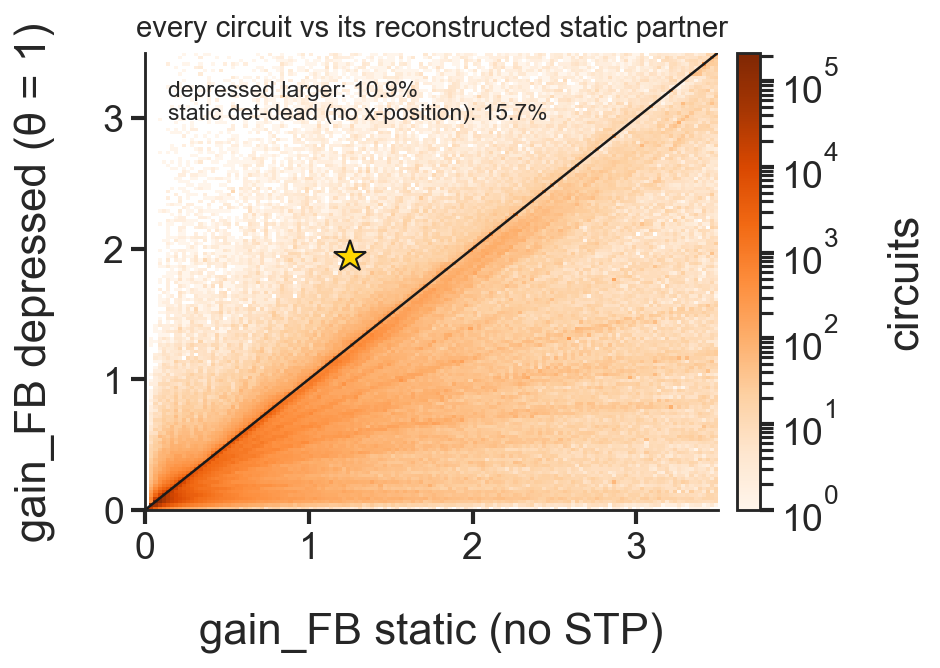

shared plane: FF-up & FB-boosted 3.3% (the wedge x > y > 0), FF-up & static-wins 81.8%, FF-down 7.6% / 7.3%; P(FF-up | p>0) = 30.0% vs P(FF-up | p<0) = 91.8%
nesting theorem: FF-up & FB-boosted with wES <= wPS: 0 of 102,535 (both conditions force wES > wPS, hence an arousal-rising FB/FF ratio)


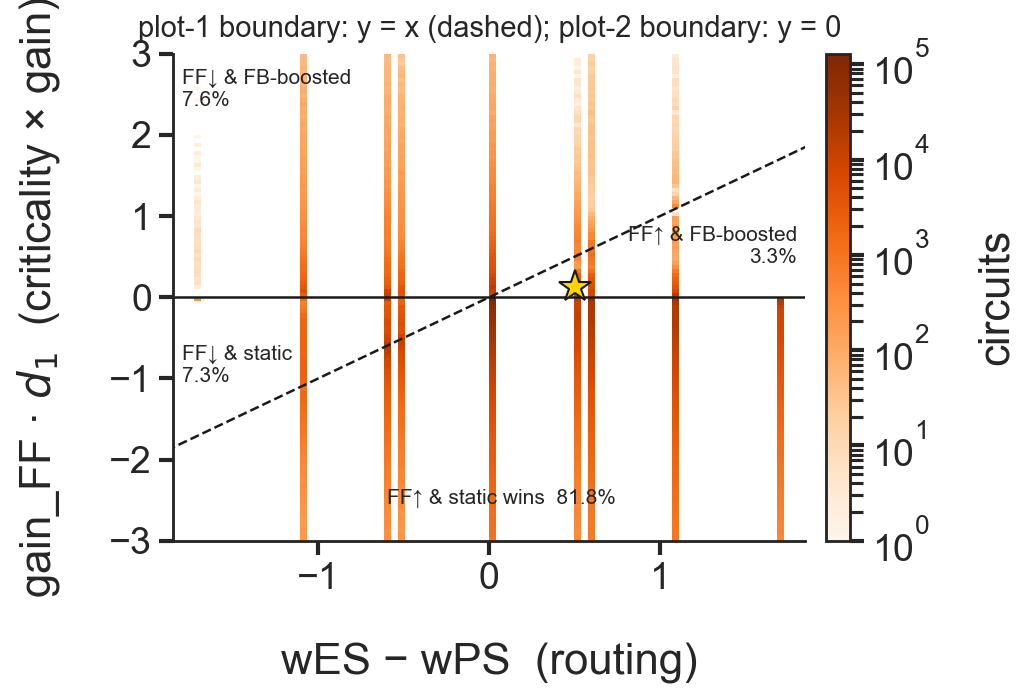

In [326]:
# Plot 2 in the grid: each circuit's static (no-STP) partner sits at k = wSP on
# the SAME coupling axis (cSP = 1), and D(k) is linear — so the static point is
# exactly reconstructible from the two stored arousal conditions. N_FB is k-free:
# depression moves gain_FB only through the determinant.
import pickle as _pkl
from matplotlib.colors import LogNorm
if "_du" not in globals():
    if not LOAD:
        raise RuntimeError("LOAD is False: run the grid simulations first "
                           "(run_uniform_grid.sh + reassemble_uniform.py, see "
                           "README) and point GRID_PATH at the resulting "
                           "full_results_arousal_ff_fb_isn_uniform.pkl")
    with open(GRID_PATH, "rb") as _f:
        _pku = _pkl.load(_f)
    _ciu = {c: i for i, c in enumerate(_pku["columns"])}
    _du = _pku["data"].astype(np.float32)

_cof = lambda U: U / (1 + U * 5.0 * 0.1)**2          # rP0 = 5 Hz, tau_SP = 100 ms
_c_lo, _c_hi = _cof(0.5), _cof(0.15)
_a_st = (1.0 - _c_lo) / (_c_hi - _c_lo)              # (k_static-k_lo)/(k_hi-k_lo): wSP-free

lam_lo, lam_hi = _du[:, _ciu["lam_low"]], _du[:, _ciu["lam_high"]]
FF_lo, FF_hi = _du[:, _ciu["gain_FF_low"]], _du[:, _ciu["gain_FF_high"]]
FB_lo, FB_hi = _du[:, _ciu["gain_FB_low"]], _du[:, _ciu["gain_FB_high"]]
wSP_c = _du[:, _ciu["wSP"]]
stable = np.isfinite(lam_lo) & np.isfinite(lam_hi) & (lam_lo <= -0.05) & (lam_hi <= -0.05)
dom = stable & (FF_lo > 0) & (FF_hi > 0) & (FB_lo > 0) & (FB_hi > 0)
m2 = dom & (wSP_c > 0)

D_hi = FB_lo[m2] / FB_hi[m2]              # D(k_hi), normalized to D(k_lo) := 1
D_st = 1 + (D_hi - 1) * _a_st             # the static determinant, same scale
FB_st = FB_lo[m2] / D_st                  # static gain_FB (meaningful where D_st > 0)
p_pos = D_hi < 1                          # det slope > 0 <=> FB rises under ACh <=> depressed > static
dead = D_st <= 0

print(f"population: {m2.sum()/1e6:.2f}M stable configs with wSP > 0 and positive gains at both ends")
print(f"depressed gain_FB > static gain_FB (the plotted behavior, p > 0): {p_pos.mean():.1%}")
print(f"static larger (det-positive static): {(~p_pos & ~dead).mean():.1%}; "
      f"static control det-certified unstable: {dead.mean():.1%}")
print("caveat: det > 0 statics can still die by oscillation (as W_B's does) — "
      "that failure is invisible to the two stored conditions")
assert not np.any(p_pos & dead)
print("exact class fact: 0 of them have p > 0 AND a det-dead static control "
      "(p > 0 means det GROWS toward the static point)")

# W_RUN's own numbers, computed directly
def _gb(c):
    r = c._compute_block("weights", c.rE0, c.rP0, c.rS0, c.rV0)
    return r["gain_FB"], r["max_ev_real"]

c_st = VIP_circuit_neuromod(W_RUN)
c_st.tau_SP = 0.0
c_st.U_SP_base = c_st.U_SP_high = 1.0
c_st.set_arousal(0.0)
gb_st, ev_st = _gb(c_st)
gb0, _ = _gb(VIP_circuit_neuromod(W_RUN, theta=0.0))
gb1, _ = _gb(VIP_circuit_neuromod(W_RUN, theta=1.0))
_cls = "p > 0: depression boosts the FB gain" if gb0 > gb_st else "p < 0: the static synapse wins"
print(f"W_RUN: static gain_FB {gb_st:.3f} (maxEV {ev_st:+.3f}, "
      f"{'stable' if ev_st <= -0.05 else 'UNSTABLE'}) vs depressed "
      f"{gb0:.3f} (θ=0) -> {gb1:.3f} (θ=1) — {_cls}")

# closed-form check: static point reconstructed from the two arousal ends (float64)
_Dh_run = gb0 / gb1
_st_rec = gb0 / (1 + (_Dh_run - 1) * _a_st)
assert abs(_st_rec - gb_st) < 1e-9, (_st_rec, gb_st)
# same check through the float16 grid storage, on one deterministic grid row
_rng = np.random.default_rng(0)
_m2idx = np.flatnonzero(m2)
_rows2 = _m2idx[(D_st > 0.5) & (FB_st > 0.2)]
_row = int(_rows2[_rng.integers(len(_rows2))])
_pw = {n: float(_du[_row, _ciu[n]]) for n in param_order}
_Wr = np.array([[_pw['wEE'], _pw['wEP'], _pw['wES'], 0.0],
                [_pw['wPE'], _pw['wPP'], _pw['wPS'], 0.0],
                [_pw['wSE'], _pw['wSP'], 0.0, _pw['wSV']],
                [_pw['wVE'], _pw['wVP'], _pw['wVS'], 0.0]])
c_rst = VIP_circuit_neuromod(_Wr)
c_rst.tau_SP = 0.0
c_rst.U_SP_base = c_rst.U_SP_high = 1.0
c_rst.set_arousal(0.0)
_gb_true = _gb(c_rst)[0]
_gb_rec = float(FB_st[np.searchsorted(_m2idx, _row)])
assert abs(_gb_rec - _gb_true) / abs(_gb_true) < 0.05, (_gb_rec, _gb_true)
print(f"reconstruction checks: W_RUN static from two ends = {_st_rec:.6f} (direct {gb_st:.6f}); "
      f"grid row {_row}: {_gb_rec:.3f} from float16 storage vs {_gb_true:.3f} direct")

fig, ax = plt.subplots(figsize=(6.8, 4.8))
FBh2 = FB_hi[m2]
mS = (D_st > 0) & (FB_st < 3.5) & (FBh2 < 3.5)
h = ax.hist2d(FB_st[mS], FBh2[mS], bins=140, range=[[0, 3.5], [0, 3.5]],
              cmap='Oranges', norm=LogNorm())
ax.plot([0, 3.5], [0, 3.5], color='k', lw=1.2)
ax.plot(gb_st, gb1, marker='*', ms=16, mfc='gold', mec='k')
ax.text(0.04, 0.94, f"depressed larger: {p_pos.mean():.1%}\nstatic det-dead (no x-position): {dead.mean():.1%}",
        transform=ax.transAxes, fontsize=11, color='0.15', va='top')
ax.set_xlabel('gain_FB static (no STP)')
ax.set_ylabel('gain_FB depressed (θ = 1)')
ax.set_title('every circuit vs its reconstructed static partner', fontsize=14, pad=8)
fig.colorbar(h[3], ax=ax, fraction=0.046, pad=0.03, label='circuits')
fig.tight_layout()
plt.show()

# the shared plane of the plot-1 and plot-2 conditions:
# x = wES - wPS (routing), y = gain_FF * d1 (gain-weighted criticality slope).
# plot 2 holds above y = 0; plot 1 holds below the diagonal y = x; both only on
# the wedge x > y > 0. x is discrete (grid weight differences): the stripes are real.
x2 = (_du[:, _ciu["wES"]] - _du[:, _ciu["wPS"]])[m2]
d1g = ((_du[:, _ciu["wEE"]] - 1) * _du[:, _ciu["wPS"]]
       - _du[:, _ciu["wES"]] * _du[:, _ciu["wPE"]])[m2]
y2 = FF_lo[m2] * d1g
ff2 = FF_hi[m2] < FF_lo[m2]              # wSP raises gain_FF (theta-independent bit)
print(f"shared plane: FF-up & FB-boosted {(ff2 & p_pos).mean():.1%} (the wedge x > y > 0), "
      f"FF-up & static-wins {(ff2 & ~p_pos).mean():.1%}, "
      f"FF-down {(~ff2 & p_pos).mean():.1%} / {(~ff2 & ~p_pos).mean():.1%}; "
      f"P(FF-up | p>0) = {ff2[p_pos].mean():.1%} vs P(FF-up | p<0) = {ff2[~p_pos].mean():.1%}")
_nest = (ff2 & p_pos & (x2 <= 0)).sum()
print(f"nesting theorem: FF-up & FB-boosted with wES <= wPS: {_nest} of {(ff2 & p_pos).sum():,} "
      f"(both conditions force wES > wPS, hence an arousal-rising FB/FF ratio)")

c_run0 = VIP_circuit_neuromod(W_RUN, theta=0.0)
r_run0 = c_run0._compute_block("weights", c_run0.rE0, c_run0.rP0, c_run0.rS0, c_run0.rV0)
x_run = W_RUN[0, 2] - W_RUN[1, 2]
y_run = r_run0["gain_FF"] * ((W_RUN[0, 0] - 1) * W_RUN[1, 2] - W_RUN[0, 2] * W_RUN[1, 0])

fig, ax = plt.subplots(figsize=(7.2, 5.0))
mV = np.abs(y2) <= 3
h = ax.hist2d(x2[mV], y2[mV], bins=[90, 120], range=[[-1.85, 1.85], [-3, 3]],
              cmap='Oranges', norm=LogNorm())
ax.axhline(0, color='k', lw=1.2)
ax.plot([-3, 3], [-3, 3], color='k', lw=1.2, ls='--')
ax.plot(x_run, y_run, marker='*', ms=16, mfc='gold', mec='k')
ax.text(1.80, 0.42, f"FF↑ & FB-boosted\n{(ff2 & p_pos).mean():.1%}", fontsize=10,
        color='0.15', ha='right')
ax.text(-0.6, -2.55, f"FF↑ & static wins  {(ff2 & ~p_pos).mean():.1%}", fontsize=10, color='0.15')
ax.text(-1.80, 2.35, f"FF↓ & FB-boosted\n{(~ff2 & p_pos).mean():.1%}", fontsize=10, color='0.15')
ax.text(-1.80, -1.05, f"FF↓ & static\n{(~ff2 & ~p_pos).mean():.1%}", fontsize=10, color='0.15')
ax.set_xlim(-1.85, 1.85)
ax.set_ylim(-3, 3)
ax.set_xlabel('wES − wPS  (routing)')
ax.set_ylabel('gain_FF · $d_1$  (criticality × gain)')
ax.set_title('plot-1 boundary: y = x (dashed); plot-2 boundary: y = 0', fontsize=14, pad=8)
fig.colorbar(h[3], ax=ax, fraction=0.046, pad=0.03, label='circuits')
fig.tight_layout()
plt.show()

del D_hi, D_st, FB_st, p_pos, dead, mS, FBh2, x2, y2, d1g, ff2, mV

## Plot 3 — does the synapse raise the routed mix?

The statistic (redefined 2026-08-19): each circuit's arousal-routed mix(θ) is compared
with its **exact $w_{SP} = 0$ partner** across the whole axis — plot 3's solid curve
against its dashed one — regardless of whether either rises or falls in θ. At power = 1
the full θ-curve follows from the two stored ends, and the ablated mix is exactly
linear (at $w_{SP}=0$ both gains are θ-flat; max stored difference 0.0 across the
grid), so the comparison is full-grid and exact.

- **The synapse raises the routed mix at every arousal level in 81.4%** of the 3.04M
  circuits with a stable positive-gain partner; it lowers it everywhere in 7.5%, and
  the curves cross in 11.0%.
- **Both endpoints are closed forms.** At θ = 0 the comparison is plot 1's condition
  ($w_{ES}-w_{PS} > g_{FF} d_1$; helps in 84.9%). At θ = 1 it compares $D(k_{\theta=1})$
  with $D(0)$, so "synapse beats ablation" ⟺ $d_1 < 0$ — **plot 2's slope with flipped
  orientation** (86.4%; equals the sign of $d_1$ in 100.0000% of resolvable cases).
  The k-axis ordering explains both at once: ablation ($k=0$) < depressed
  ($c_{SP}w_{SP}$) < static ($w_{SP}$) sit on one determinant line, so for the
  $d_1<0$ majority $gain_{FB}$ is ordered ablated < depressed < static — the
  depressing synapse beats its ablation *and* loses to its static self, both facts
  from one sign.
- **Channel endpoint facts** (3.14M positive-gain $w_{SP}>0$): arousal suppresses
  $gain_{FF}$ in 85.1% (the plot-1 sign bit run backwards) and raises $gain_{FB}$ in
  only 10.9% (the plot-2 $p>0$ class — $N_{FB}$ is θ-invariant, only the determinant
  moves).
- **The dominance flip is a selected phenotype**: 47,238 configs (1.5% of the
  positive-gain $w_{SP}>0$ population; 3.6% on the original grid) cross from FF- to
  FB-dominant along the axis, governed by the **exact** law
  sign(Δratio) = sign($w_{ES}-w_{PS}$): 0 violations above float16 resolution in
  2.04M configs.

population: 3.04M positive-gain wSP > 0 circuits with a stable, positive-gain wSP = 0 partner (of 10.59M stable)
the synapse raises the routed mix at EVERY arousal level in 81.4%, lowers it everywhere in 7.5%, curves cross in 11.0%
endpoints: synapse helps at theta=0 in 84.9% (plot-1 condition), at theta=1 in 86.4% — and the theta=1 bit equals [d1 < 0] in 100.0000% (exact law; rest float16 ties)
one slope, three points: for the d1 < 0 majority, D falls along ablation -> depressed -> static, so gain_FB is ordered ablated < depressed < static — the synapse beats its ablation AND loses to its static self, both from sign(d1)
channels (positive-gain wSP > 0, 3.14M): arousal suppresses gain_FF in 85.1% (plot-1 sign bit), raises gain_FB in 10.9% (plot-2 p > 0 class)
FF->FB dominance flip along arousal: 1.50% (47,238 configs)
ratio law sign(d ratio) = sign(wES - wPS): 0 violations above float16 resolution in 2.04M configs with wES != wPS
wSP = 0 anchor: max |gain_FF_high - gain_FF_low| = 0.0e+

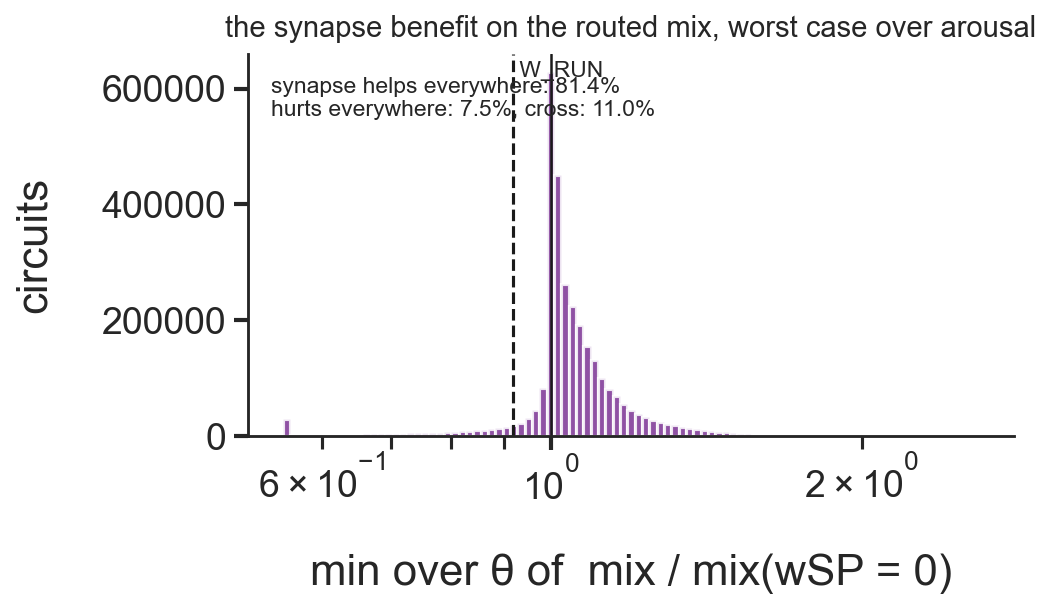

In [327]:
# Plot 3 in the grid: does the synapse raise the routed mix? Each circuit is
# compared with its exact wSP = 0 partner across the whole arousal axis
# (mix(theta) reconstructed from the two stored ends; the ablated mix is exactly
# linear). The k-axis ordering ablation(0) < depressed(cSP*wSP) < static(wSP)
# puts both controls on the SAME determinant line D(k): at theta = 1 the synapse
# beats its ablation iff d1 < 0 — the plot-2 slope read from the other side.
import pickle as _pkl
if "_du" not in globals():
    if not LOAD:
        raise RuntimeError("LOAD is False: run the grid simulations first "
                           "(run_uniform_grid.sh + reassemble_uniform.py, see "
                           "README) and point GRID_PATH at the resulting "
                           "full_results_arousal_ff_fb_isn_uniform.pkl")
    with open(GRID_PATH, "rb") as _f:
        _pku = _pkl.load(_f)
    _ciu = {c: i for i, c in enumerate(_pku["columns"])}
    _du = _pku["data"].astype(np.float32)

_cof = lambda U: U / (1 + U * 5.0 * 0.1)**2
_c_lo, _c_hi = _cof(0.5), _cof(0.15)
_beta = lambda th: (_cof(0.5 - 0.35 * th) - _c_lo) / (_c_hi - _c_lo)   # wSP-free

lam_lo, lam_hi = _du[:, _ciu["lam_low"]], _du[:, _ciu["lam_high"]]
FF_lo, FF_hi = _du[:, _ciu["gain_FF_low"]], _du[:, _ciu["gain_FF_high"]]
FB_lo, FB_hi = _du[:, _ciu["gain_FB_low"]], _du[:, _ciu["gain_FB_high"]]
wSP_c = _du[:, _ciu["wSP"]]
stable = np.isfinite(lam_lo) & np.isfinite(lam_hi) & (lam_lo <= -0.05) & (lam_hi <= -0.05)
dom = stable & (FF_lo > 0) & (FF_hi > 0) & (FB_lo > 0) & (FB_hi > 0)

# exact wSP = 0 partner values, broadcast to row space (partner is theta-flat)
_dims3 = (4, 4, 4, 4, 4, 4, 4, 5, 5, 4, 4, 4)
_v3 = lambda a: np.moveaxis(a.reshape(_dims3), 7, 11).reshape(-1, 5)
_idx3 = np.moveaxis(np.arange(_du.shape[0]).reshape(_dims3), 7, 11).reshape(-1, 5)
FFa = np.empty_like(FF_lo)
FBa = np.empty_like(FB_lo)
lama = np.empty_like(lam_lo)
FFa[_idx3.ravel()] = np.repeat(_v3(FF_lo)[:, 0], 5)
FBa[_idx3.ravel()] = np.repeat(_v3(FB_lo)[:, 0], 5)
lama[_idx3.ravel()] = np.repeat(_v3(lam_lo)[:, 0], 5)
mA = dom & (wSP_c > 0) & np.isfinite(lama) & (lama <= -0.05) & (FFa > 0) & (FBa > 0)
print(f"population: {mA.sum()/1e6:.2f}M positive-gain wSP > 0 circuits with a stable, "
      f"positive-gain wSP = 0 partner (of {stable.sum()/1e6:.2f}M stable)")

# mix(theta) vs the (exactly linear) ablated mix, 21 theta points
DhA = FB_lo[mA] / FB_hi[mA]
NFl, NFh, NB = FF_lo[mA], FF_hi[mA] * DhA, FB_lo[mA]
FFam, FBam = FFa[mA], FBa[mA]
above = np.ones(mA.sum(), bool)
below = np.ones(mA.sum(), bool)
min_ratio = np.full(mA.sum(), np.inf, np.float32)
for th in np.linspace(0, 1, 21):
    b = _beta(th)
    mixf = ((1 - th) * (NFl + (NFh - NFl) * b) + th * NB) / (1 + (DhA - 1) * b)
    mixa = (1 - th) * FFam + th * FBam
    above &= mixf > mixa
    below &= mixf < mixa
    min_ratio = np.minimum(min_ratio, mixf / mixa)
print(f"the synapse raises the routed mix at EVERY arousal level in {above.mean():.1%}, "
      f"lowers it everywhere in {below.mean():.1%}, curves cross in {1 - above.mean() - below.mean():.1%}")

# the two endpoints are exact closed forms: theta = 0 is plot 1's condition;
# theta = 1 compares D(k_hi) with D(0), i.e. the sign of d1 — plot 2's slope
# with flipped orientation (ablation sits at k = 0, the static control at k = wSP)
d1r = ((_du[:, _ciu["wEE"]] - 1) * _du[:, _ciu["wPS"]]
       - _du[:, _ciu["wES"]] * _du[:, _ciu["wPE"]])[mA]
bit0 = FF_lo[mA] > FFam
bit1 = FB_hi[mA] > FBam
rel1 = np.abs(FB_hi[mA] - FBam) / FB_hi[mA]
agree = (bit1 == (d1r < 0)) | (rel1 <= 3e-3)
print(f"endpoints: synapse helps at theta=0 in {bit0.mean():.1%} (plot-1 condition), "
      f"at theta=1 in {bit1.mean():.1%} — and the theta=1 bit equals [d1 < 0] in "
      f"{agree.mean():.4%} (exact law; rest float16 ties)")
print("one slope, three points: for the d1 < 0 majority, D falls along "
      "ablation -> depressed -> static, so gain_FB is ordered ablated < depressed < static — "
      "the synapse beats its ablation AND loses to its static self, both from sign(d1)")

# channel endpoint facts, the dominance flip, and the exact ratio law
m3 = dom & (wSP_c > 0)
print(f"channels (positive-gain wSP > 0, {m3.sum()/1e6:.2f}M): arousal suppresses gain_FF in "
      f"{(FF_hi[m3] < FF_lo[m3]).mean():.1%} (plot-1 sign bit), raises gain_FB in "
      f"{(FB_hi[m3] > FB_lo[m3]).mean():.1%} (plot-2 p > 0 class)")
ratio_lo, ratio_hi = FB_lo[m3] / FF_lo[m3], FB_hi[m3] / FF_hi[m3]
cross = (ratio_lo < 1) & (ratio_hi > 1)
print(f"FF->FB dominance flip along arousal: {cross.mean():.2%} ({cross.sum():,} configs)")
dwq = _du[:, _ciu["wES"]][m3] - _du[:, _ciu["wPS"]][m3]
dr = ratio_hi - ratio_lo
rel = np.abs(dr) / np.maximum(ratio_lo, ratio_hi)
nz = dwq != 0
viol = ((np.sign(dwq[nz]) != np.sign(dr[nz])) & (rel[nz] > 3e-3)).sum()
print(f"ratio law sign(d ratio) = sign(wES - wPS): {viol} violations above float16 "
      f"resolution in {nz.sum()/1e6:.2f}M configs with wES != wPS")
z0 = np.isfinite(FF_lo) & (wSP_c == 0)
print(f"wSP = 0 anchor: max |gain_FF_high - gain_FF_low| = "
      f"{np.abs(FF_hi[z0] - FF_lo[z0]).max():.1e} — the ablated gains are theta-flat, "
      f"so the ablated mix is exactly linear in theta")

# W_RUN vs its own ablation, plus the closed-form mid-axis reconstruction check
theta101 = np.linspace(0, 1, 101)
s_run = VIP_circuit_neuromod(W_RUN).sweep_arousal(theta101)
_W0r = W_RUN.copy()
_W0r[2, 1] = 0.0
s_ab = VIP_circuit_neuromod(_W0r).sweep_arousal(theta101)
_rat = s_run["gain_mix"] / s_ab["gain_mix"]
print(f"W_RUN: mix/ablated-mix ranges {np.min(_rat):.2f}-{np.max(_rat):.2f} -> "
      + ("synapse helps at every theta" if np.min(_rat) > 1 else
         "synapse hurts at every theta" if np.max(_rat) < 1 else "the curves cross"))
_Dh_run = s_run["gain_FB"][0] / s_run["gain_FB"][-1]
_b5 = _beta(0.5)
_mix5 = (0.5 * (s_run["gain_FF"][0] + (s_run["gain_FF"][-1] * _Dh_run - s_run["gain_FF"][0]) * _b5)
         + 0.5 * s_run["gain_FB"][0]) / (1 + (_Dh_run - 1) * _b5)
assert abs(_mix5 - s_run["gain_mix"][50]) < 1e-9, (_mix5, s_run["gain_mix"][50])
print(f"reconstruction check at theta = 0.5: {_mix5:.6f} vs direct {s_run['gain_mix'][50]:.6f}")

fig, ax = plt.subplots(figsize=(7.2, 4.4))
bins = np.geomspace(0.55, 2.6, 96)
ax.hist(np.clip(min_ratio, bins[0], bins[-1]), bins=bins, color=color_mix, alpha=0.85)
ax.axvline(1, color='k', lw=1.2)
ax.axvline(np.min(_rat), color='k', lw=1.5, ls='--')
ax.text(np.min(_rat), 0.94, ' W_RUN', fontsize=11,
        transform=ax.get_xaxis_transform(), color='0.15')
ax.text(0.03, 0.94, f"synapse helps everywhere: {above.mean():.1%}\nhurts everywhere: "
        f"{below.mean():.1%}, cross: {1 - above.mean() - below.mean():.1%}",
        transform=ax.transAxes, fontsize=11, color='0.15', va='top')
ax.set_xscale('log')
ax.set_xlabel('min over θ of  mix / mix(wSP = 0)')
ax.set_ylabel('circuits')
ax.set_title('the synapse benefit on the routed mix, worst case over arousal',
             fontsize=14, pad=8)
fig.tight_layout()
plt.show()

del DhA, NFl, NFh, NB, FFam, FBam, above, below, min_ratio, mixf, mixa, FFa, FBa, lama, d1r, bit0, bit1, rel1, agree, ratio_lo, ratio_hi, dr, dwq, rel, nz

## Plot 4 — what does arousal do to stability, in general?

**Stability along arousal is not an independent property.** Quasi-static stability
depends on (θ, $w_{SP}$) only through the coupling $k = c_{SP}(θ)\,w_{SP}$ (the stretch
law, verified on W_RUN to 1e-12 below), so the θ-axis of plot 4 re-reads plot 1's
stability-vs-$w_{SP}$ curve right-to-left: ACh lowers $c_{SP}$ ×0.41 and slides the
circuit **left** along its own stability-vs-coupling curve $S(k)$. Consequences, on the
full uniform grid:

- Across all 10.59M stable configs the endpoint comparison is an even split — arousal
  stabilizes 50.5% (52.7% on the original grid) — because the $S(k)$ slope itself
  splits the grid.
- The split is **slaved to plot 1's classes, near-perfectly, on both grids**: among the
  mono-up families ("the synapse stabilizes") arousal *destabilizes* 98.7% of member
  configs; among the mono-down families it *stabilizes* 98.7% (99.5% both ways on the
  original grid — the small residual is float16 ties plus curve segments the coarse
  axis misclassifies). "The synapse raises stability" and "arousal raises stability"
  are mutually exclusive by the stretch law.
- At $w_{SP} = 0$ arousal has no circuit left to act on: lam is bit-identical at both
  ends across the grid — the dashed ablation line of plot 4 is exactly flat.
- Caveat: `lam` is the quasi-static 4×4 rate Jacobian (the 6-state STP/filter dynamics
  can add Hopf instabilities it cannot see). Between the endpoints, $S(k)$ is unimodal
  in ~99.5% of circuits (81-point sweep, 10k sample of the original grid), so endpoint
  stability certifies the axis interior except a rare interior-valley class.

arousal stabilizes (lam_high < lam_low) in 50.5% of 10.59M stable configs — an even split with no preferred direction
stretch-law anchor: wSP = 0 rows have max |lam_high - lam_low| = 0.0e+00 (identical by construction — the ablated dashed line of plot 4 is exactly flat)
  synapse stabilizes (mono up, W_RUN's class): arousal destabilizes in 98.67% of 2.08M member configs
  synapse destabilizes (mono down): arousal stabilizes in 98.68% of 4.22M member configs
both near 100%: theta and wSP move the SAME curve S(k) in opposite directions (ACh lowers cSP, sliding the circuit left along its own stability curve)
W_RUN: stability falls 0.146 -> 0.114 along arousal — anti-slaved to its stability-vs-wSP slope (plot 1) by the stretch law
stretch law verified on W_RUN to 1e-12: maxEV(theta, wSP) = maxEV(0, wSP*cSP(theta)/cSP(0))
caveat: all lam values are the quasi-static 4x4 rate Jacobian; between the endpoints, S(k) is unimodal in ~99.5% of circuits, so endpoint stability certifies the axis inte

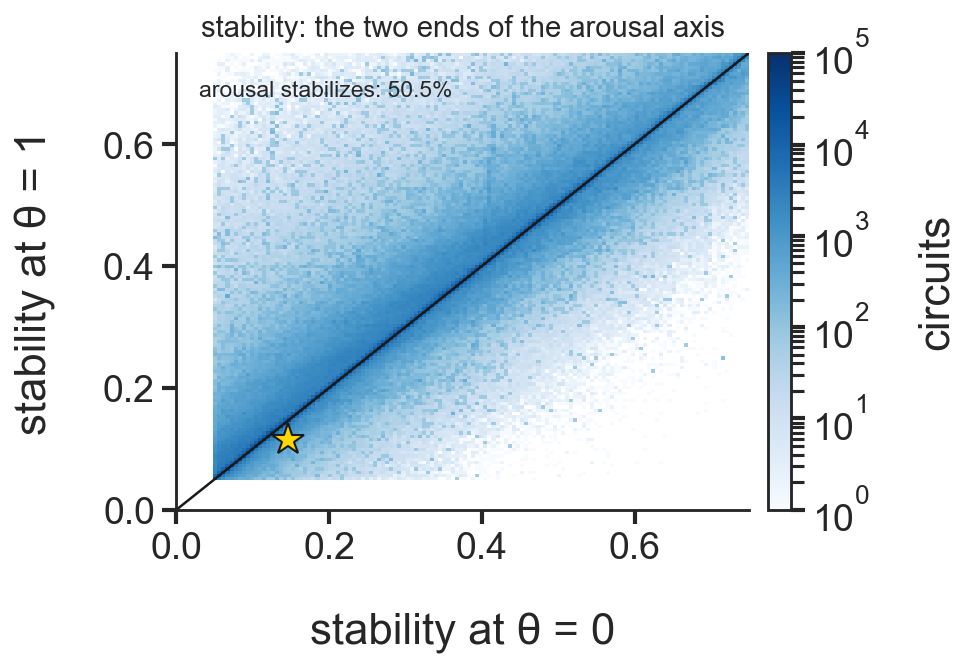

In [328]:
# Plot 4 in the grid: stability along arousal is NOT an independent property —
# quasi-static stability depends on (theta, wSP) only through k = cSP(theta)*wSP
# (the stretch law), so the theta-axis re-reads the stability-vs-coupling curve
# right-to-left: "the synapse stabilizes" forces "arousal destabilizes", exactly.
import pickle as _pkl
from matplotlib.colors import LogNorm
if "_du" not in globals():
    if not LOAD:
        raise RuntimeError("LOAD is False: run the grid simulations first "
                           "(run_uniform_grid.sh + reassemble_uniform.py, see "
                           "README) and point GRID_PATH at the resulting "
                           "full_results_arousal_ff_fb_isn_uniform.pkl")
    with open(GRID_PATH, "rb") as _f:
        _pku = _pkl.load(_f)
    _ciu = {c: i for i, c in enumerate(_pku["columns"])}
    _du = _pku["data"].astype(np.float32)
_dims = (4, 4, 4, 4, 4, 4, 4, 5, 5, 4, 4, 4)

lam_lo, lam_hi = _du[:, _ciu["lam_low"]], _du[:, _ciu["lam_high"]]
wSP_c = _du[:, _ciu["wSP"]]
stable = np.isfinite(lam_lo) & np.isfinite(lam_hi) & (lam_lo <= -0.05) & (lam_hi <= -0.05)

frac_stab = (lam_hi[stable] < lam_lo[stable]).mean()
print(f"arousal stabilizes (lam_high < lam_low) in {frac_stab:.1%} of {stable.sum()/1e6:.2f}M "
      f"stable configs — an even split with no preferred direction")

# stretch-law anchor: at wSP = 0 arousal has no circuit left to act on
z0 = np.isfinite(lam_lo) & (wSP_c == 0)
print(f"stretch-law anchor: wSP = 0 rows have max |lam_high - lam_low| = "
      f"{np.abs(lam_hi[z0] - lam_lo[z0]).max():.1e} (identical by construction — "
      f"the ablated dashed line of plot 4 is exactly flat)")

# the coupling: stability direction along wSP vs along theta, on the same families
# classified in the plot-1 cell (mono-up families = W_RUN's class)
def _wsp_view(col):
    return np.moveaxis(_du[:, _ciu[col]].reshape(_dims), 7, 11).reshape(-1, 5)

lamF0 = _wsp_view("lam_low")
ax_ok0 = (np.isfinite(lamF0) & (lamF0 <= -0.05)).all(axis=1)
sgn = np.sign(np.diff(-lamF0, axis=1))
fam_up = ax_ok0 & np.all(sgn >= 0, axis=1) & (sgn.max(axis=1) > 0)
fam_dn = ax_ok0 & np.all(sgn <= 0, axis=1) & (sgn.min(axis=1) < 0)
idxs = np.moveaxis(np.arange(_du.shape[0]).reshape(_dims), 7, 11).reshape(-1, 5)
for fam, lbl, direction in ((fam_up, "synapse stabilizes (mono up, W_RUN's class)", "destabilizes"),
                            (fam_dn, "synapse destabilizes (mono down)", "stabilizes")):
    rows = idxs[fam][:, 1:].ravel()
    mm = stable[rows]
    d_th = lam_hi[rows][mm] - lam_lo[rows][mm]
    frac = (d_th > 0).mean() if direction == "destabilizes" else (d_th < 0).mean()
    print(f"  {lbl}: arousal {direction} in {frac:.2%} of {mm.sum()/1e6:.2f}M member configs")
print("both near 100%: theta and wSP move the SAME curve S(k) in opposite directions "
      "(ACh lowers cSP, sliding the circuit left along its own stability curve)")

# W_RUN: the forced trade-off, plus an exact stretch-law check
_cof = lambda U: U / (1 + U * 5.0 * 0.1)**2
s_run = VIP_circuit_neuromod(W_RUN).sweep_arousal(np.linspace(0, 1, 101))
_dir = "falls" if -s_run["maxEV"][-1] < -s_run["maxEV"][0] else "rises"
print(f"W_RUN: stability {_dir} {-s_run['maxEV'][0]:.3f} -> {-s_run['maxEV'][-1]:.3f} along "
      f"arousal — anti-slaved to its stability-vs-wSP slope (plot 1) by the stretch law")
for th in (0.3, 0.7, 1.0):
    c_th = VIP_circuit_neuromod(W_RUN, theta=th)
    s_th = c_th._compute_block("weights", c_th.rE0, c_th.rP0, c_th.rS0, c_th.rV0)["max_ev_real"]
    W_eq = W_RUN.copy()
    W_eq[2, 1] = W_RUN[2, 1] * _cof(0.5 - 0.35 * th) / _cof(0.5)
    c_eq = VIP_circuit_neuromod(W_eq, theta=0.0)
    s_eq = c_eq._compute_block("weights", c_eq.rE0, c_eq.rP0, c_eq.rS0, c_eq.rV0)["max_ev_real"]
    assert abs(s_th - s_eq) < 1e-12, (th, s_th, s_eq)
print("stretch law verified on W_RUN to 1e-12: maxEV(theta, wSP) = maxEV(0, wSP*cSP(theta)/cSP(0))")
print("caveat: all lam values are the quasi-static 4x4 rate Jacobian; between the "
      "endpoints, S(k) is unimodal in ~99.5% of circuits, so endpoint stability "
      "certifies the axis interior except a ~0.3% valley class")

fig, ax = plt.subplots(figsize=(6.8, 4.8))
s0, s1 = -lam_lo[stable], -lam_hi[stable]
lim = 0.75
mS = (s0 < lim) & (s1 < lim)
h = ax.hist2d(s0[mS], s1[mS], bins=140, range=[[0, lim], [0, lim]],
              cmap='Blues', norm=LogNorm())
ax.plot([0, lim], [0, lim], color='k', lw=1.2)
ax.plot(-s_run["maxEV"][0], -s_run["maxEV"][-1], marker='*', ms=16, mfc='gold', mec='k')
ax.text(0.04, 0.94, f"arousal stabilizes: {frac_stab:.1%}", transform=ax.transAxes,
        fontsize=11, color='0.15', va='top')
ax.set_xlabel('stability at θ = 0')
ax.set_ylabel('stability at θ = 1')
ax.set_title('stability: the two ends of the arousal axis', fontsize=14, pad=8)
fig.colorbar(h[3], ax=ax, fraction=0.046, pad=0.03, label='circuits')
fig.tight_layout()
plt.show()

del lamF0, ax_ok0, sgn, fam_up, fam_dn, idxs, s0, s1, mS

## What the synapse buys: the arousal modulation range

The matched-static control in plots 3–4 makes the comparison fair at rest: a static
synapse with the depressed circuit's effective weight ($w_{\text{eff}} = c_{SP}(0)\,w_{SP}$)
is *identical* at θ = 0 — and then arousal happens only to the depressed circuit,
because only it carries a release probability for ACh to act on. This cell quantifies
the reachable range: the per-circuit % change of each channel gain between the two ends
of the arousal axis, across the grid. **Every static synapse, of any weight, scores
exactly zero on all of it** (the $w_{SP}=0$ rows are bit-exactly θ-flat; the same holds
for any static weight by θ-invariance of its $k$).

- $gain_{FF}$: median −8.8% (IQR −26..−1%); at least 10% modulation in 52% of circuits,
  at least 20% in 35%.
- $gain_{FB}$: median −5.4%; ≥10% in 38% (moves only through the determinant).
- FB/FF rebalancing: median ≈0 but ≥10% in 36% — the $w_{ES}>w_{PS}$ half does the
  rebalancing, per the exact ratio law.
- The depth is powered by one parameter: $c_{SP}$ travels 0.320 → 0.130 (×0.41), so a
  single $U$ converts the ACh signal into up to tens-of-percent circuit reconfiguration
  with zero anatomical change. W_RUN (dashed) is an extreme router: $gain_{FF}$ −76%,
  $gain_{FB}$ +3%, ratio +322%.

**Reading the figure:** each curve's height at $x$ is the fraction of circuits whose gain arousal can retune by at least $x\%$ — e.g. the $gain_{FF}$ curve passes 10% at height 0.52. The dotted flat line at zero is every static synapse: no circuit, at any weight, gets any modulation from it. Stars mark W_RUN.

This is the depression term's purpose stated as a number: it *is* the circuit's
modulation range — remove it, and the range is exactly zero.

population: 3.14M positive-gain wSP > 0 circuits; the coupling moves x0.41 along arousal
  gain_FF: median -8.8% (IQR -26.3..-1.3%); |change| >= 10% in 52.0%, >= 20% in 34.7%
  gain_FB: median -5.4% (IQR -14.9..-0.8%); |change| >= 10% in 38.0%, >= 20% in 18.9%
  FB/FF ratio: median +0.1% (IQR -0.0..+14.3%); |change| >= 10% in 36.1%, >= 20% in 22.5%
any static synapse scores exactly 0 on all three: wSP = 0 rows have max |gain change| = 0.0e+00
W_RUN: gain_FF -37.9%, gain_FB +12.0%, FB/FF ratio +80.4% along arousal
signs: arousal LOWERS gain_FF in 85% and gain_FB in 87% of circuits — the curves below use magnitudes


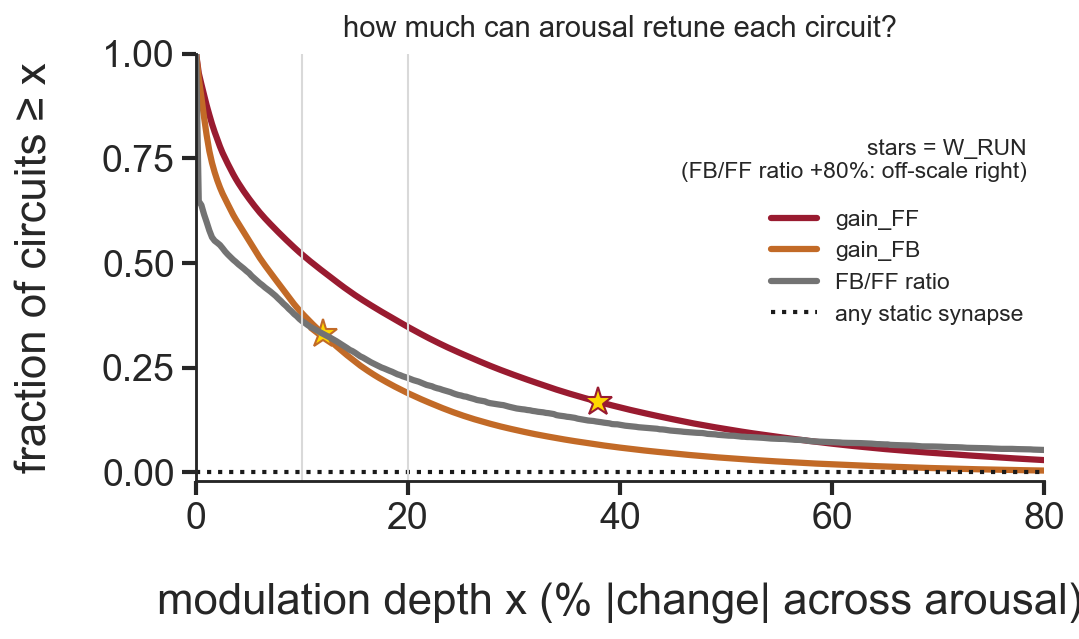

In [329]:
# The modulation range: what the depressing synapse buys that NO static synapse
# can — the arousal-reachable change of the circuit's channel gains. A static
# synapse of any weight has no U for ACh to act on, so every depth below is
# exactly 0 for it (the wSP = 0 rows of the grid are bit-exactly theta-flat).
import pickle as _pkl
if "_du" not in globals():
    if not LOAD:
        raise RuntimeError("LOAD is False: run the grid simulations first "
                           "(run_uniform_grid.sh + reassemble_uniform.py, see "
                           "README) and point GRID_PATH at the resulting "
                           "full_results_arousal_ff_fb_isn_uniform.pkl")
    with open(GRID_PATH, "rb") as _f:
        _pku = _pkl.load(_f)
    _ciu = {c: i for i, c in enumerate(_pku["columns"])}
    _du = _pku["data"].astype(np.float32)

lam_lo, lam_hi = _du[:, _ciu["lam_low"]], _du[:, _ciu["lam_high"]]
FF_lo, FF_hi = _du[:, _ciu["gain_FF_low"]], _du[:, _ciu["gain_FF_high"]]
FB_lo, FB_hi = _du[:, _ciu["gain_FB_low"]], _du[:, _ciu["gain_FB_high"]]
wSP_c = _du[:, _ciu["wSP"]]
stable = np.isfinite(lam_lo) & np.isfinite(lam_hi) & (lam_lo <= -0.05) & (lam_hi <= -0.05)
dom = stable & (FF_lo > 0) & (FF_hi > 0) & (FB_lo > 0) & (FB_hi > 0)
m5 = dom & (wSP_c > 0)

dFF = 100 * (FF_hi[m5] / FF_lo[m5] - 1)      # % change of gain_FF along arousal
dFB = 100 * (FB_hi[m5] / FB_lo[m5] - 1)      # % change of gain_FB along arousal
drt = 100 * ((FB_hi[m5] / FF_hi[m5]) / (FB_lo[m5] / FF_lo[m5]) - 1)   # FB/FF rebalance

print(f"population: {m5.sum()/1e6:.2f}M positive-gain wSP > 0 circuits; the coupling "
      f"moves x{(0.15/(1+0.15*0.5)**2) / (0.5/(1+0.5*0.5)**2):.2f} along arousal")
for name, dx in (("gain_FF", dFF), ("gain_FB", dFB), ("FB/FF ratio", drt)):
    q1, q2, q3 = np.percentile(dx, (25, 50, 75))
    print(f"  {name}: median {q2:+.1f}% (IQR {q1:+.1f}..{q3:+.1f}%); "
          f"|change| >= 10% in {(np.abs(dx) >= 10).mean():.1%}, >= 20% in {(np.abs(dx) >= 20).mean():.1%}")
z5 = (wSP_c == 0) & np.isfinite(FF_lo)
print(f"any static synapse scores exactly 0 on all three: wSP = 0 rows have "
      f"max |gain change| = {max(np.abs(FF_hi[z5] - FF_lo[z5]).max(), np.abs(FB_hi[z5] - FB_lo[z5]).max()):.1e}")

# W_RUN's own depths
s5r = VIP_circuit_neuromod(W_RUN).sweep_arousal(np.linspace(0, 1, 101))
w_dFF = 100 * (s5r["gain_FF"][-1] / s5r["gain_FF"][0] - 1)
w_dFB = 100 * (s5r["gain_FB"][-1] / s5r["gain_FB"][0] - 1)
w_drt = 100 * (s5r["ratio"][-1] / s5r["ratio"][0] - 1)
print(f"W_RUN: gain_FF {w_dFF:+.1f}%, gain_FB {w_dFB:+.1f}%, FB/FF ratio {w_drt:+.1f}% along arousal")
print(f"signs: arousal LOWERS gain_FF in {(dFF < 0).mean():.0%} and gain_FB in "
      f"{(dFB < 0).mean():.0%} of circuits — the curves below use magnitudes")

# survival curves: fraction of circuits whose gain can be retuned by AT LEAST x%
# by moving arousal across its full range. Reading example: gain_FF crosses
# x = 10% at 0.52 -> arousal re-tunes the FF gain by >= 10% in 52% of circuits.
# A static synapse of any weight is theta-flat, so its curve is the flat zero line.
fig, ax = plt.subplots(figsize=(7.4, 4.6))
xs = np.linspace(0, 80, 321)
for dx, col, lbl, w_val in ((dFF, color_FF, 'gain_FF', abs(w_dFF)),
                            (dFB, color_FB, 'gain_FB', abs(w_dFB)),
                            (drt, '0.45', 'FB/FF ratio', abs(w_drt))):
    a = np.sort(np.abs(dx))
    surv = 1.0 - np.searchsorted(a, xs) / len(a)
    ax.plot(xs, surv, color=col, label=lbl)
    if w_val <= xs[-1]:
        ax.plot(w_val, 1.0 - np.searchsorted(a, w_val) / len(a), marker='*',
                ms=14, mfc='gold', mec=col)
ax.plot([0, 80], [0, 0], color='k', ls=':', lw=2, label='any static synapse')
ax.axvline(10, color='0.85', lw=1)
ax.axvline(20, color='0.85', lw=1)
_note = "stars = W_RUN" + "".join(
    f"\n({lbl} {v:+.0f}%: off-scale right)"
    for lbl, v in (("gain_FF", w_dFF), ("gain_FB", w_dFB), ("FB/FF ratio", w_drt))
    if abs(v) > 80)
ax.text(0.98, 0.80, _note, transform=ax.transAxes, fontsize=11, color='0.15',
        ha='right', va='top')
ax.set_xlabel('modulation depth x (% |change| across arousal)')
ax.set_ylabel('fraction of circuits ≥ x')
ax.set_xlim(0, 80)
ax.set_ylim(-0.02, 1.0)
ax.set_title('how much can arousal retune each circuit?', fontsize=14, pad=8)
ax.legend(fontsize=11)
fig.tight_layout()
plt.show()

del dFF, dFB, drt, m5, z5